In [ ]:
import pandas as pd
import numpy as np
file_path = '/EuropeanBank.csv'
df = pd.read_csv(file_path)
print(df.head())

   Year  CustomerId   Surname  CreditScore Geography  Gender  Age  Tenure  \
0  2025    15634602  Hargrave          619    France  Female   42       2   
1  2025    15647311      Hill          608     Spain  Female   41       1   
2  2025    15619304      Onio          502    France  Female   42       8   
3  2025    15701354      Boni          699    France  Female   39       1   
4  2025    15737888  Mitchell          850     Spain  Female   43       2   

     Balance  NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  \
0       0.00              1          1               1        101348.88   
1   83807.86              1          0               1        112542.58   
2  159660.80              3          1               0        113931.57   
3       0.00              2          0               0         93826.63   
4  125510.82              1          1               1         79084.10   

   Exited  
0       1  
1       0  
2       1  
3       0  
4       0  


In [ ]:
df.shape

(10000, 14)

In [ ]:
df.dtypes

,0
Year,int64
CustomerId,int64
Surname,object
CreditScore,int64
Geography,object
Gender,object
Age,int64
Tenure,int64
Balance,float64
NumOfProducts,int64


In [ ]:
df.isna().sum()

,0
Year,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


In [ ]:
##dropping unnessary columns
df = df.drop(['CustomerId','Surname'],axis=1)
df.head()

,Year,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
print(df["Exited"].mean())   # baseline churn rate

0.2037


In [ ]:
from sklearn.model_selection import train_test_split
 #splitting before-hand to avoid leakage
X = df.drop(columns=["Exited"])
y = df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(y_train.mean(), y_test.mean())   #churn rates in train and test data are almost identical

0.20375 0.2035


#ADDING ENGINEERED FEATURES

In [ ]:
def add_features(d):
    d = d.copy()
    elipson = 1e-15
    d['Balance_to_Salary'] = d['Balance']/(d['EstimatedSalary'] + elipson)
    d['Product_Density'] = d['NumOfProducts']/(d['Tenure'] + 1)
    d['Age_Tenure_Ratio'] = d['Tenure']/(d['Age'])
    d['Age_Tenure_Interaction'] = d['Age']*d['Tenure']
    d['Engagement_Product_Interaction'] = d['IsActiveMember'] * d['NumOfProducts']
    return d

In [ ]:
X_train = add_features(X_train)
X_train.head()

,Year,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Balance_to_Salary,Product_Density,Age_Tenure_Ratio,Age_Tenure_Interaction,Engagement_Product_Interaction
2151,2025,753,France,Male,57,7,0.00,1,1,0,159475.08,0.000000,0.125000,0.122807,399,0
8392,2025,739,Germany,Male,32,3,102128.27,1,1,0,63981.37,1.596219,0.250000,0.093750,96,0
5006,2025,755,Germany,Female,37,0,113865.23,2,1,1,117396.25,0.969922,2.000000,0.000000,0,2
4117,2025,561,France,Male,37,5,0.00,2,1,0,83093.25,0.000000,0.333333,0.135135,185,0
7182,2025,692,Germany,Male,49,6,110540.43,2,0,1,107472.99,1.028541,0.285714,0.122449,294,2


In [ ]:
X_test  = add_features(X_test)
X_test.head()

,Year,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Balance_to_Salary,Product_Density,Age_Tenure_Ratio,Age_Tenure_Interaction,Engagement_Product_Interaction
5702,2025,585,France,Male,36,7,0.00,2,1,0,94283.09,0.000000,0.250000,0.194444,252,0
3667,2025,525,Germany,Male,33,4,131023.76,2,0,0,55072.93,2.379096,0.400000,0.121212,132,0
1617,2025,557,Spain,Female,40,4,0.00,2,0,1,105433.53,0.000000,0.400000,0.100000,160,2
5673,2025,639,Spain,Male,34,5,139393.19,2,0,0,33950.08,4.105828,0.333333,0.147059,170,0
4272,2025,640,Spain,Female,34,3,77826.80,1,1,1,168544.85,0.461757,0.250000,0.088235,102,1


<Axes: >

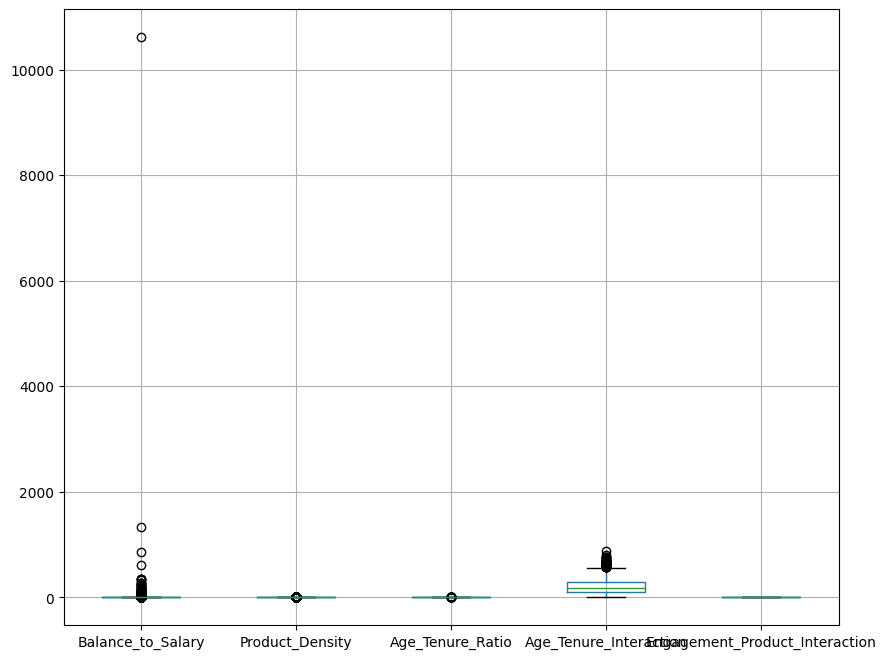

In [ ]:
##visualising new features
feature_cols = ['Balance_to_Salary','Product_Density','Age_Tenure_Ratio','Age_Tenure_Interaction','Engagement_Product_Interaction']
X_train.boxplot(column=feature_cols,figsize=(10,8))

In [ ]:
X_train['Balance_to_Salary'].describe()

,Balance_to_Salary
count,8000.000000
mean,4.221891
std,120.885989
min,0.000000
25%,0.000000
50%,0.749749
75%,1.511564
max,10614.655440


In [ ]:
keep = X_train["Balance_to_Salary"] < 5000
X_train, y_train = X_train[keep], y_train[keep]
#removed one row with ratio > 10,000 due to near-zero salary

<Axes: >

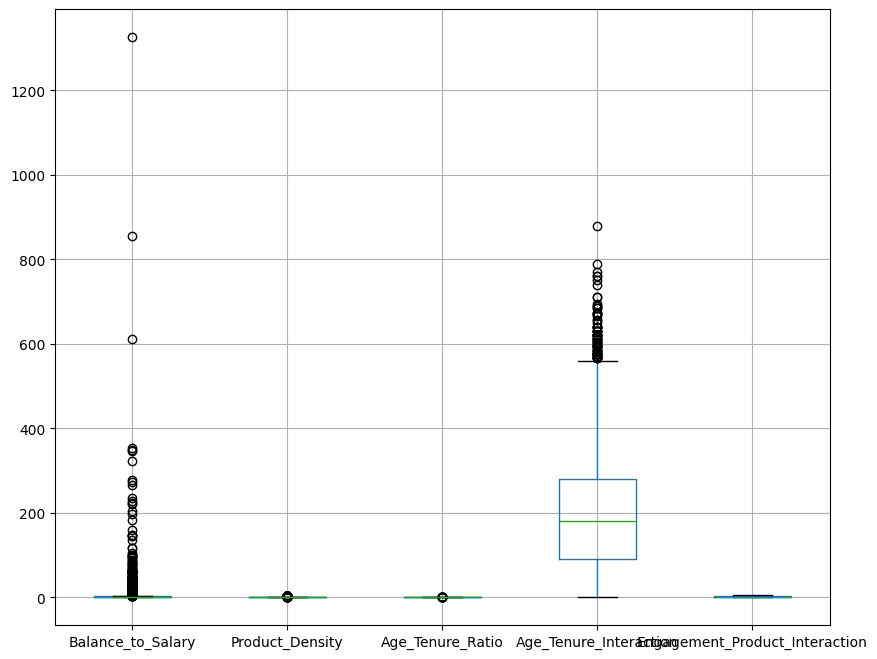

In [ ]:
X_train.boxplot(column=feature_cols,figsize=(10,8))

,0
Balance_to_Salary,"Axes(0.125,0.53;0.227941x0.35)"
Product_Density,"Axes(0.398529,0.53;0.227941x0.35)"
Age_Tenure_Ratio,"Axes(0.672059,0.53;0.227941x0.35)"
Age_Tenure_Interaction,"Axes(0.125,0.11;0.227941x0.35)"
Engagement_Product_Interaction,"Axes(0.398529,0.11;0.227941x0.35)"


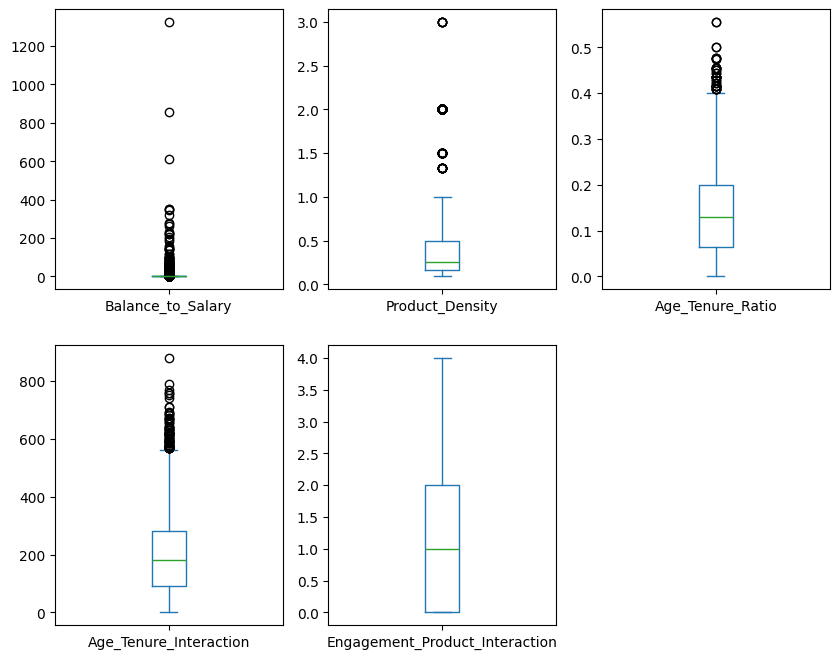

In [ ]:
X_train[feature_cols].plot(kind='box', subplots = True, sharey = False, figsize=(10,8),layout=(2,3))

In [ ]:
X_train[feature_cols].describe()

,Balance_to_Salary,Product_Density,Age_Tenure_Ratio,Age_Tenure_Interaction,Engagement_Product_Interaction
count,7999.000000,7999.000000,7999.000000,7999.000000,7999.000000
mean,2.895421,0.365871,0.137818,195.287411,0.790349
std,23.179908,0.334630,0.089239,128.901195,0.869981
min,0.000000,0.090909,0.000000,0.000000,0.000000
25%,0.000000,0.166667,0.064516,90.000000,0.000000
50%,0.749735,0.250000,0.129032,180.000000,1.000000
75%,1.510950,0.500000,0.200000,280.000000,2.000000
max,1326.102779,3.000000,0.555556,880.000000,4.000000


In [ ]:
print(X_train[feature_cols].skew().round(2))                 # |skew| > 1 = strongly skewed
print("Share of exact zeros:", (X_train["Balance_to_Salary"] == 0).mean().round(3))

Balance_to_Salary                 34.95
Product_Density                    2.80
Age_Tenure_Ratio                   0.56
Age_Tenure_Interaction             0.71
Engagement_Product_Interaction     0.63
dtype: float64
Share of exact zeros: 0.361


Observations:
1) 'Balance_to_Salary' has a heavily right-skewed distribution due to 0 balance accounts
2) 'Product_Density' is moderately skewed

In [ ]:
for d in (X_train, X_test):
    d["Log_Balance_to_Salary"] = np.log1p(d["Balance_to_Salary"])
    d["Log_Product_Density"]   = np.log(d["Product_Density"])

In [ ]:
X_train[["Balance_to_Salary","Log_Balance_to_Salary","Product_Density" ,"Log_Product_Density"]].describe()

,Balance_to_Salary,Log_Balance_to_Salary,Product_Density,Log_Product_Density
count,7999.000000,7999.000000,7999.000000,7999.000000
mean,2.895421,0.658794,0.365871,-1.283617
std,23.179908,0.773157,0.334630,0.706687
min,0.000000,0.000000,0.090909,-2.397895
25%,0.000000,0.000000,0.166667,-1.791759
50%,0.749735,0.559464,0.250000,-1.386294
75%,1.510950,0.920661,0.500000,-0.693147
max,1326.102779,7.190753,3.000000,1.098612


,0
Balance_to_Salary,"Axes(0.125,0.53;0.227941x0.35)"
Log_Balance_to_Salary,"Axes(0.398529,0.53;0.227941x0.35)"
Product_Density,"Axes(0.672059,0.53;0.227941x0.35)"
Log_Product_Density,"Axes(0.125,0.11;0.227941x0.35)"


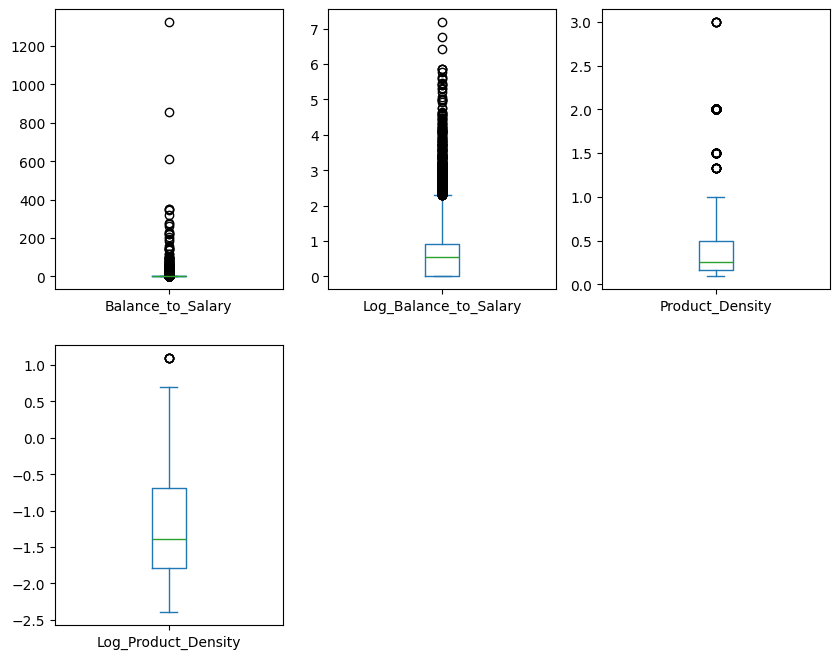

In [ ]:
X_train[["Balance_to_Salary","Log_Balance_to_Salary","Product_Density" ,"Log_Product_Density"]].plot(kind='box', subplots = True, sharey = False, figsize=(10,8),layout=(2,3))

In [ ]:
print(X_train[["Log_Balance_to_Salary", "Log_Product_Density"]].skew().round(2))

Log_Balance_to_Salary    2.20
Log_Product_Density      0.55
dtype: float64


In [ ]:
# make sure X and y rows line up after the manual row drop
print("Missing values:", int(X_train.isna().sum().sum()))
y_train = y_train.loc[X_train.index]

Missing values: 0


#Baseline Model: Logistic Regession

In [ ]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate


raw_num  = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary"]
eng_num  = ["Log_Balance_to_Salary", "Log_Product_Density",
            "Age_Tenure_Ratio", "Age_Tenure_Interaction"]
cat_cols = ["Geography", "Gender"]
keep_cols = ["NumOfProducts", "HasCrCard", "IsActiveMember",
             "Engagement_Product_Interaction"]

def make_model(scale, keep):
    prep = ColumnTransformer([
        ("scale", StandardScaler(), scale),
        ("cat",   OneHotEncoder(drop="first"), cat_cols),
        ("keep",  "passthrough", keep),
    ])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=1000))])

# baseline: raw + engineered features
log_reg = make_model(raw_num + eng_num, keep_cols)
log_reg.fit(X_train, y_train)

# metrics, via stratified 5-fold cross-validation on the training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
res = cross_validate(log_reg, X_train, y_train, cv=cv, scoring=metrics)
for m in metrics:
    print(f"{m:10s} {res['test_' + m].mean():.3f} ± {res['test_' + m].std():.3f}")

# output: probability (0-1) plus a threshold-based churn flag
proba = log_reg.predict_proba(X_train)[:, 1]
flag = (proba >= 0.5).astype(int)        # 0.5 is a placeholder; tune it from the precision/recall trade-off
print(pd.DataFrame({"churn_probability": proba[:5].round(3), "churn_flag": flag[:5]}))

accuracy   0.818 ± 0.004
precision  0.644 ± 0.027
recall     0.237 ± 0.015
f1         0.346 ± 0.020
roc_auc    0.775 ± 0.011
   churn_probability  churn_flag
0              0.414           0
1              0.269           0
2              0.095           0
3              0.141           0
4              0.326           0


In [ ]:
no_eng = make_model(raw_num, ["NumOfProducts", "HasCrCard", "IsActiveMember"])
res2 = cross_validate(no_eng, X_train, y_train, cv=cv, scoring=["roc_auc"])
print("With engineered features   :", res["test_roc_auc"].mean().round(3))
print("Without engineered features:", res2["test_roc_auc"].mean().round(3))

With engineered features   : 0.775
Without engineered features: 0.762


## Logistic Regression (Baseline): Summary

**Fitting**
- All engineered features were kept alongside the raw ones. The two heavily right-skewed derived features (Balance_to_Salary and Product_Density) were log-transformed first.
- Continuous variables were standardised, Geography and Gender were one-hot encoded, and binary or count variables were passed through unchanged.
- The model was fitted as a single pipeline, so the scaler learns its statistics from the training data only.
- Performance was estimated by 5-fold stratified cross-validation on the training set. The test set was not touched.

**Performance (5-fold CV)**

| Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|
| 0.818 ± 0.004 | 0.644 ± 0.027 | 0.237 ± 0.015 | 0.346 ± 0.020 | 0.775 ± 0.011 |

- Accuracy looks respectable but is not very informative. With about 20% churners, predicting "nobody churns" already scores about 80%.
- At the default 0.5 threshold the model flags few customers: when it flags someone it is right about two times in three (precision 0.64), but it catches only about 1 in 4 real churners (recall 0.24). The predicted probabilities rarely exceed 0.5, which is why recall is low. The cutoff is too strict for this problem.
- ROC-AUC (0.775) is the fairest summary: the model ranks risky customers above safe ones reasonably well, but not sharply.
- Removing the engineered features lowers ROC-AUC from 0.775 to 0.762. The gain of about 0.013 is modest and close to the fold-to-fold spread (±0.011), so the derived features help a little in a linear model.

**Interpretation of coefficients**
Coefficients are log-odds. An odds ratio above 1 raises churn odds and below 1 lowers them. Standardised features are read per one standard deviation, and binary features per 0→1 change.


**Shortcomings**
- **Linearity:** the model assumes each feature changes the log-odds at a constant rate. Churn is unlikely to behave that way for product count and age.
- **No automatic interactions:** it can only use the interactions we engineered by hand, and those added little (AUC +0.013).
- **Low recall at the default threshold:** many churners are missed unless the threshold is lowered. The 0.5 cutoff is a placeholder and the final one will be chosen in the evaluation step from the precision/recall trade-off.


**Role in the project:** the logistic regression is the interpretability benchmark. The tree-based and boosting models need to beat its ROC-AUC of 0.775, and its signs and sizes give a first view of the key churn drivers: inactivity, age, Germany and gender.

#Descision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

cat_cols = ["Geography", "Gender"]
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary",
            "NumOfProducts", "HasCrCard", "IsActiveMember",
            "Balance_to_Salary", "Product_Density", "Age_Tenure_Ratio",
            "Age_Tenure_Interaction", "Engagement_Product_Interaction"]

prep_tree = ColumnTransformer([
    ("cat", OneHotEncoder(), cat_cols),        # no drop="first": trees don't suffer from the dummy trap
    ("num", "passthrough", num_cols),
])

def make_tree(**params):
    return Pipeline([("prep", prep_tree),
                     ("model", DecisionTreeClassifier(random_state=42, **params))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# An unrestricted tree: it can keep splitting until every leaf is pure
res = cross_validate(make_tree(), X_train, y_train, cv=cv,
                     scoring="roc_auc", return_train_score=True)
print(f"Unrestricted tree | train AUC {res['train_score'].mean():.3f} "
      f"| validation AUC {res['test_score'].mean():.3f}")

Unrestricted tree | train AUC 1.000 | validation AUC 0.685


In [ ]:
#tuning the tree
param_grid = {
    "model__max_depth":        [3, 4, 5, 6, 8],
    "model__min_samples_leaf": [10, 25, 50, 100],
}
grid = GridSearchCV(make_tree(), param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print(f"Best CV ROC-AUC: {grid.best_score_:.3f}   (logistic baseline: 0.775)")
best_tree = grid.best_estimator_

Best settings: {'model__max_depth': 6, 'model__min_samples_leaf': 10}
Best CV ROC-AUC: 0.837   (logistic baseline: 0.775)


In [ ]:
res = cross_validate(best_tree, X_train, y_train, cv=cv, scoring=metrics)
for m in metrics:
    print(f"{m:10s} {res['test_' + m].mean():.3f} ± {res['test_' + m].std():.3f}")

oof = cross_val_predict(best_tree, X_train, y_train, cv=cv, method="predict_proba")[:, 1] #oof stands for out of fold
for t in [0.5, 0.4, 0.3, 0.25, 0.2]:
    pred = (oof >= t).astype(int)
    print(f"threshold {t:.2f} | precision {precision_score(y_train, pred):.3f} "
          f"| recall {recall_score(y_train, pred):.3f} | F1 {f1_score(y_train, pred):.3f}")

print(confusion_matrix(y_train, (oof >= 0.5).astype(int)))   # rows: actual, columns: predicted

accuracy   0.857 ± 0.007
precision  0.771 ± 0.021
recall     0.425 ± 0.043
f1         0.546 ± 0.037
roc_auc    0.837 ± 0.013
threshold 0.50 | precision 0.768 | recall 0.427 | F1 0.549
threshold 0.40 | precision 0.720 | recall 0.480 | F1 0.576
threshold 0.30 | precision 0.535 | recall 0.646 | F1 0.585
threshold 0.25 | precision 0.504 | recall 0.697 | F1 0.585
threshold 0.20 | precision 0.454 | recall 0.749 | F1 0.565
[[6160  210]
 [ 934  695]]


|--- num__Age <= 42.50
|   |--- num__NumOfProducts <= 2.50
|   |   |--- num__NumOfProducts <= 1.50
|   |   |   |--- cat__Geography_Germany <= 0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- cat__Geography_Germany >  0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- num__NumOfProducts >  1.50
|   |   |   |--- num__Balance_to_Salary <= 0.53
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- num__Balance_to_Salary >  0.53
|   |   |   |   |--- truncated branch of depth 3
|   |--- num__NumOfProducts >  2.50
|   |   |--- num__Balance <= 55948.91
|   |   |   |--- num__EstimatedSalary <= 132695.48
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- num__EstimatedSalary >  132695.48
|   |   |   |   |--- class: 1
|   |   |--- num__Balance >  55948.91
|   |   |   |--- num__Age_Tenure_Interaction <= 96.00
|   |   |   |   |--- class: 1
|   |   |   |--- num__Age_Tenure_Interaction >  96.00
|   |   |   |   |--- truncated branch of d

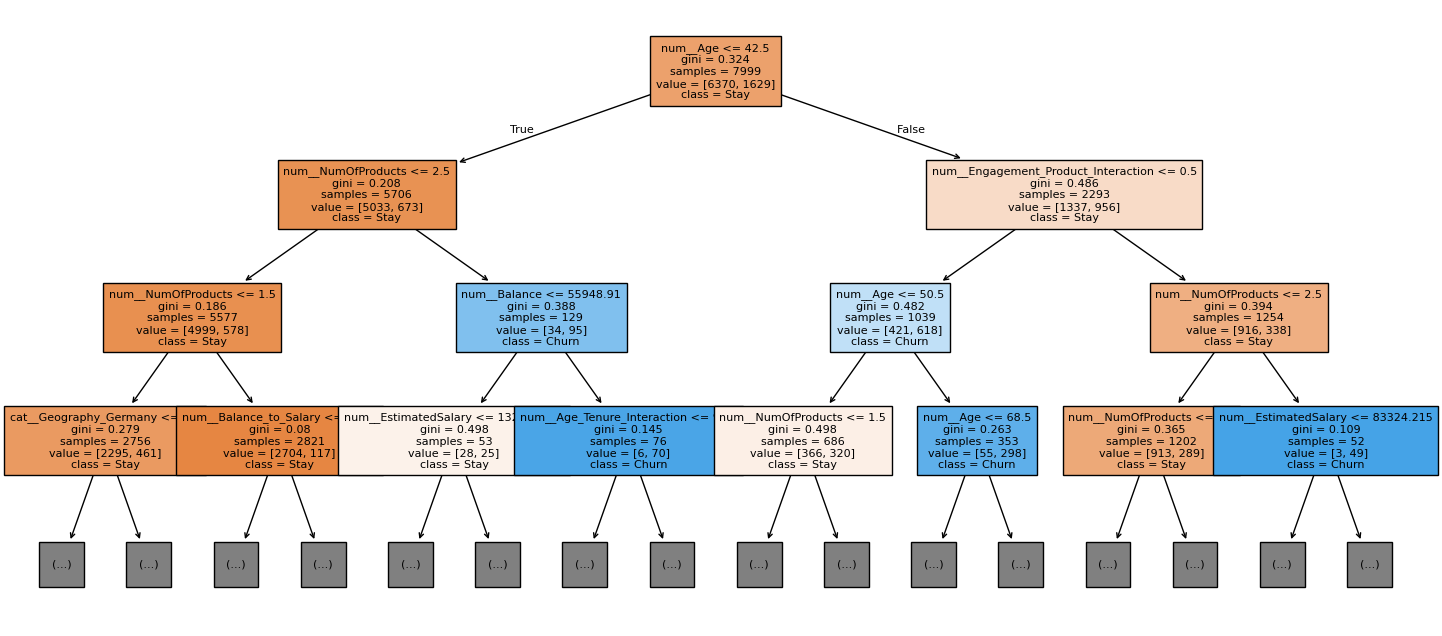

num__Age                               0.391
num__NumOfProducts                     0.305
num__Engagement_Product_Interaction    0.123
num__Balance                           0.067
cat__Geography_Germany                 0.055
num__Balance_to_Salary                 0.038
num__EstimatedSalary                   0.008
num__Age_Tenure_Interaction            0.006
num__CreditScore                       0.004
cat__Gender_Male                       0.002
dtype: float64


In [ ]:
import matplotlib.pyplot as plt
tree = best_tree.named_steps["model"]
names = best_tree.named_steps["prep"].get_feature_names_out()

# reading what the tree learned
print(export_text(tree, feature_names=list(names), max_depth=3))
plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=names, class_names=["Stay", "Churn"],
          filled=True, max_depth=3, fontsize=8)
plt.show()

#Importance = total impurity reduction each feature produced
#this cab be interpreted as a measure to quantify how much of a key distintor a variable is
imp = pd.Series(tree.feature_importances_, index=names).sort_values(ascending=False)
print(imp.head(10).round(3))

## Decision Tree: Summary

**Performance**
- The tree beats the baseline on every metric. ROC-AUC rises by about 0.06, which is well beyond the fold-to-fold spread (±0.013). A non-linear model captures patterns the linear baseline could not, such as the product-count effect and interactions.

- At the default 0.5 threshold the tree catches 695 of 1,629 churners (recall 0.43) and raises 210 false alarms (precision 0.77). That is a better balance than the baseline's, but it still misses more than half of the real churners.

**Threshold**
- Lowering the cutoff trades precision for recall. F1 peaks at about 0.585 for thresholds of 0.25 to 0.30. At 0.30, recall is 0.65 and precision is 0.54.
- The right threshold depends on the cost of a retention offer versus the value of a saved customer, so the final choice is deferred to the evaluation step.

**Observations from top nodes:**
- The first split is on **Age (about 42.5)**, followed by **NumOfProducts** at 1.5 and 2.5. Customers with 3 or more products reach churn leaves quickly, consistent with the U-shaped product-count pattern seen in the logistic diagnostics.
- Among customers over 42, the split on **Engagement_Product_Interaction ≤ 0.5** separates inactive customers from active ones. Inactive customers over about 68 end in a "stay" leaf.
- Geography_Germany and Balance also appear as early splits.

**Feature importance (impurity-based, provisional)**

- Of the engineered features, **Engagement_Product_Interaction** is clearly useful, and Balance_to_Salary adds some. Age_Tenure_Interaction contributes almost nothing. Tenure, CreditScore and Gender are negligible.
- IsActiveMember does not appear separately, likely because Engagement_Product_Interaction already carries the activity information.

**Caveats**
- Impurity-based importance favours features with many distinct values, so these rankings will be checked with permutation importance and SHAP later.
- The same folds were used for tuning and reporting, so the scores are slightly optimistic. The untouched test set gives the final estimate.



In [ ]:
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (StratifiedKFold, RandomizedSearchCV,
                                     cross_validate, cross_val_predict)


y_train = y_train.loc[X_train.index]          # make sure X and y rows line up

cat_cols = ["Geography", "Gender"]
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary",
            "NumOfProducts", "HasCrCard", "IsActiveMember",
            "Balance_to_Salary", "Product_Density", "Age_Tenure_Ratio",
            "Age_Tenure_Interaction", "Engagement_Product_Interaction"]

prep_tree = ColumnTransformer([
    ("cat", OneHotEncoder(), cat_cols),        # forests need no scaling or log transforms
    ("num", "passthrough", num_cols),
])

def make_rf(n_estimators=300, **params):
    return Pipeline([("prep", prep_tree),
                     ("model", RandomForestClassifier(n_estimators=n_estimators,
                                                      random_state=42, n_jobs=-1, **params))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # same folds as the other models

In [ ]:
#tuning
param_dist = {
    "model__max_depth":        [6, 8, 12],
    "model__min_samples_leaf": [3, 5, 10, 20],
    "model__max_features":     ["sqrt", 0.5],
}
t0 = time.time()
search = RandomizedSearchCV(make_rf(n_estimators=100), param_dist, n_iter=8,
                            cv=cv, scoring="roc_auc", n_jobs=1,
                            random_state=42, verbose=2)
search.fit(X_train, y_train)
print("Best settings:", search.best_params_)
print(f"Best CV ROC-AUC (100 trees): {search.best_score_:.3f}  |  tuning took {time.time()-t0:.0f} s")

Fitting 5 folds for each of 8 candidates, totalling 40 fits
[CV] END model__max_depth=8, model__max_features=sqrt, model__min_samples_leaf=3; total time=   1.1s
[CV] END model__max_depth=8, model__max_features=sqrt, model__min_samples_leaf=3; total time=   0.6s
[CV] END model__max_depth=8, model__max_features=sqrt, model__min_samples_leaf=3; total time=   0.6s
[CV] END model__max_depth=8, model__max_features=sqrt, model__min_samples_leaf=3; total time=   0.6s
[CV] END model__max_depth=8, model__max_features=sqrt, model__min_samples_leaf=3; total time=   0.6s
[CV] END model__max_depth=12, model__max_features=sqrt, model__min_samples_leaf=3; total time=   0.7s
[CV] END model__max_depth=12, model__max_features=sqrt, model__min_samples_leaf=3; total time=   0.7s
[CV] END model__max_depth=12, model__max_features=sqrt, model__min_samples_leaf=3; total time=   0.7s
[CV] END model__max_depth=12, model__max_features=sqrt, model__min_samples_leaf=3; total time=   0.7s
[CV] END model__max_depth=1

In [ ]:
best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
best_rf = make_rf(n_estimators=300, **best_params)
best_rf.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cat', OneHotEncoder(),
                                                  ['Geography', 'Gender']),
                                                 ('num', 'passthrough',
                                                  ['CreditScore', 'Age',
                                                   'Tenure', 'Balance',
                                                   'EstimatedSalary',
                                                   'NumOfProducts', 'HasCrCard',
                                                   'IsActiveMember',
                                                   'Balance_to_Salary',
                                                   'Product_Density',
                                                   'Age_Tenure_Ratio',
                                                   'Age_Tenure_Interaction',
                                                   'Engagement_Product_Interaction'])])),
                ('model',
                 RandomForestClassifier(max_depth=8, max_features=0.5,
                                        min_samples_leaf=5, n_estimators=300,
                                        n_jobs=-1, random_state=42))])

In [ ]:
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]
res = cross_validate(best_rf, X_train, y_train, cv=cv, scoring=scoring)
for m in scoring:
    print(f"{m:18s} {res['test_' + m].mean():.3f} ± {res['test_' + m].std():.3f}")

accuracy           0.860 ± 0.009
precision          0.773 ± 0.032
recall             0.446 ± 0.034
f1                 0.565 ± 0.033
roc_auc            0.858 ± 0.007
average_precision  0.682 ± 0.013


In [ ]:
oof = cross_val_predict(best_rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
for t in [0.5, 0.4, 0.3, 0.25, 0.2]:
    pred = (oof >= t).astype(int)
    print(f"threshold {t:.2f} | precision {precision_score(y_train, pred):.3f} "
          f"| recall {recall_score(y_train, pred):.3f} | F1 {f1_score(y_train, pred):.3f}")

threshold 0.50 | precision 0.773 | recall 0.446 | F1 0.566
threshold 0.40 | precision 0.699 | recall 0.522 | F1 0.598
threshold 0.30 | precision 0.603 | recall 0.629 | F1 0.616
threshold 0.25 | precision 0.541 | recall 0.691 | F1 0.607
threshold 0.20 | precision 0.477 | recall 0.760 | F1 0.586


In [ ]:
from sklearn.metrics import roc_auc_score

Xt = best_rf.named_steps["prep"].transform(X_train)
rf_oob = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=42,
                                n_jobs=-1, **best_params).fit(Xt, y_train)
print("OOB ROC-AUC:", round(roc_auc_score(y_train, rf_oob.oob_decision_function_[:, 1]), 3))

OOB ROC-AUC: 0.86


In [ ]:
rows = {"Random forest": {m: res["test_" + m].mean() for m in scoring}}   # reuse the CV results above
for name, mdl in {"Logistic regression": log_reg, "Decision tree": best_tree}.items():
    r = cross_validate(mdl, X_train, y_train, cv=cv, scoring=scoring)
    rows[name] = {m: r["test_" + m].mean() for m in scoring}
print(pd.DataFrame(rows).T.loc[["Logistic regression", "Decision tree", "Random forest"]].round(3))

names = best_rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best_rf.named_steps["model"].feature_importances_, index=names)
print(imp.sort_values(ascending=False).head(10).round(3))

                     accuracy  precision  recall     f1  roc_auc  \
Logistic regression     0.818      0.644   0.237  0.346    0.775   
Decision tree           0.857      0.771   0.425  0.546    0.837   
Random forest           0.860      0.773   0.446  0.565    0.858   

                     average_precision  
Logistic regression              0.505  
Decision tree                    0.639  
Random forest                    0.682  
num__Age                               0.336
num__NumOfProducts                     0.218
num__Engagement_Product_Interaction    0.092
num__Balance                           0.064
num__IsActiveMember                    0.055
cat__Geography_Germany                 0.046
num__Balance_to_Salary                 0.043
num__CreditScore                       0.029
num__EstimatedSalary                   0.027
num__Age_Tenure_Interaction            0.024
dtype: float64


## Random Forest: Key Observations, Interpretation, Conclusions and Caveats

**Setup:** 300 trees, tuned by a randomised search (8 settings, 100 trees each) and refitted with 300 trees, using the same stratified 5-fold CV as the other models.

| Metric (CV) | Logistic regression | Decision tree | Random forest |
|---|---|---|---|
| Accuracy | 0.818 | 0.857 | 0.860 |
| Precision | 0.644 | 0.771 | 0.773 |
| Recall | 0.237 | 0.425 | 0.446 |
| F1 | 0.346 | 0.546 | 0.565 |
| ROC-AUC | 0.775 | 0.837 | **0.858** |
| Average precision | 0.505 | 0.639 | **0.682** |

### Key observations
- **The forest has the best ranking quality so far.** ROC-AUC rises from 0.837 (tree) to 0.858, and average precision from 0.639 to 0.682. Both gains are larger than the fold-to-fold spread.
- **At the default 0.5 threshold, the forest is only slightly better than the tree.** Accuracy (0.860 vs 0.857) and precision (0.773 vs 0.771) are essentially tied, and recall improves modestly (0.446 vs 0.425). The forest's advantage is in how well it ranks customers, not in the 0.5 cutoff.


- **The spread across folds is smaller.** The ROC-AUC standard deviation falls from ±0.013 (tree) to ±0.007, which is the expected effect of averaging many trees (variance reduction).
- **The out-of-bag ROC-AUC (0.86) matches the CV ROC-AUC (0.858).** Two independent estimates agree, so the CV score looks stable.
- **Threshold behaviour:** F1 peaks at a threshold of 0.30 (0.616), with precision 0.603 and recall 0.629. At 0.30 the tree had precision 0.535 and recall 0.646, so the forest gives noticeably fewer false alarms at a similar catch rate. Its precision–recall trade-off also changes more smoothly with the threshold.
- **Recall at 0.5 is still low** (0.446). More than half of the real churners are missed unless the threshold is lowered.

### Feature importance (impurity-based, provisional)
- The top three features are the same as in the tree: **Age (0.336)**, **NumOfProducts (0.218)** and **Engagement_Product_Interaction (0.092)**. Together they carry about 65% of the importance, less concentrated than in the tree (about 82%).
- Importance is spread more evenly. IsActiveMember (0.055) now appears separately, and Balance (0.064), Geography_Germany (0.046) and Balance_to_Salary (0.043) follow.
- Among the engineered features, Engagement_Product_Interaction is clearly useful, and Balance_to_Salary ranks above the raw EstimatedSalary and CreditScore. Age_Tenure_Interaction contributes little (0.024). Product_Density, Age_Tenure_Ratio and Tenure are outside the top ten.

### Interpretation
- A forest can capture non-linear effects and interactions, such as the product-count pattern and the age thresholds seen in the tree. Averaging many different trees makes those patterns more reliable than a single tree's.
- The forest spreads credit across correlated features, which explains why the importance ranking looks flatter than the tree's.
- The drivers are consistent across the models: product holdings, age, and engagement (activity) lead, with geography and balance behind them.

### Conclusions
- The random forest is the **best model so far** and clearly beats the logistic baseline (ROC-AUC 0.858 vs 0.775). The gain over the decision tree is real but moderate.
- Of the metrics at the default threshold, recall remains the weak point, so the final threshold needs to come from the precision/recall trade-off (an F1 optimum around 0.30 is a first indication) and the cost of retention offers.
- The engineered features earn their place mainly through Engagement_Product_Interaction and, to a lesser extent, Balance_to_Salary.

### Caveats
- **Optimistic scores:** the same folds were used for tuning and for reporting, so the numbers are slightly optimistic. The untouched test set will give the final estimate.
- **Light tuning:** the search tried only 8 settings with 100 trees each, so the best configuration may not be the optimum. Check whether the chosen settings sit at the edge of the ranges.
- **Importance bias:** impurity-based importance favours features with many distinct values (Balance, CreditScore, EstimatedSalary), so the small importances of the weak features are partly an artefact. Permutation importance and SHAP will check the ranking.
- **Calibration not yet checked:** a forest averages the votes of many trees, which tends to pull probabilities toward the middle, so a threshold such as 0.30 should be treated as a score cutoff and not a literal probability until calibration is examined in the evaluation step.
- **F1 is not the business objective:** the F1-maximising threshold may differ from the one that maximises campaign value.
- **Not final:** gradient boosting is still to be compared, and the test set has not yet been used.


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import (StratifiedKFold, RandomizedSearchCV,
                                     cross_validate, cross_val_predict)


cat_cols = ["Geography", "Gender"]
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary",
            "NumOfProducts", "HasCrCard", "IsActiveMember",
            "Balance_to_Salary", "Product_Density", "Age_Tenure_Ratio",
            "Age_Tenure_Interaction", "Engagement_Product_Interaction"]

prep_tree = ColumnTransformer([
    ("cat", OneHotEncoder(), cat_cols),
    ("num", "passthrough", num_cols),
])

def make_gb(**params):
    return Pipeline([("prep", prep_tree),
                     ("model", GradientBoostingClassifier(
                         n_estimators=300,          # an upper limit; early stopping decides the real number
                         n_iter_no_change=20,       # stop if the validation loss hasn't improved for 20 trees
                         validation_fraction=0.1,   # 10% of each training fold is held back for that check
                         random_state=42, **params))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
# ---------- 2. Tune: 8 sampled settings ----------
param_dist = {
    "model__learning_rate":    [0.03, 0.05, 0.1],   # how much each tree is allowed to correct
    "model__max_depth":        [2, 3, 4],           # boosting works best with shallow trees
    "model__min_samples_leaf": [5, 10, 20],
    "model__subsample":        [0.7, 1.0],          # fraction of rows used per tree; below 1 adds randomness
}
t0 = time.time()
search = RandomizedSearchCV(make_gb(), param_dist, n_iter=8, cv=cv,
                            scoring="roc_auc", n_jobs=1, random_state=42, verbose=2)
search.fit(X_train, y_train)
print("Best settings:", search.best_params_)
print(f"Best CV ROC-AUC: {search.best_score_:.3f}  |  tuning took {time.time()-t0:.0f} s")

Fitting 5 folds for each of 8 candidates, totalling 40 fits
[CV] END model__learning_rate=0.05, model__max_depth=2, model__min_samples_leaf=5, model__subsample=1.0; total time=   2.3s
[CV] END model__learning_rate=0.05, model__max_depth=2, model__min_samples_leaf=5, model__subsample=1.0; total time=   2.0s
[CV] END model__learning_rate=0.05, model__max_depth=2, model__min_samples_leaf=5, model__subsample=1.0; total time=   3.2s
[CV] END model__learning_rate=0.05, model__max_depth=2, model__min_samples_leaf=5, model__subsample=1.0; total time=   2.9s
[CV] END model__learning_rate=0.05, model__max_depth=2, model__min_samples_leaf=5, model__subsample=1.0; total time=   2.9s
[CV] END model__learning_rate=0.1, model__max_depth=4, model__min_samples_leaf=5, model__subsample=1.0; total time=   1.5s
[CV] END model__learning_rate=0.1, model__max_depth=4, model__min_samples_leaf=5, model__subsample=1.0; total time=   0.9s
[CV] END model__learning_rate=0.1, model__max_depth=4, model__min_samples_

In [ ]:
# ---------- 3. Final model ----------
best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
best_gb = make_gb(**best_params).fit(X_train, y_train)
print("Trees actually used:", best_gb.named_steps["model"].n_estimators_)

Trees actually used: 125


In [ ]:
# ---------- 4. Evaluate: the guide's metrics, 5-fold CV ----------
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc",
           "average_precision", "neg_brier_score"]
res = cross_validate(best_gb, X_train, y_train, cv=cv, scoring=scoring,
                     return_train_score=True)
for m in scoring:
    sign = -1 if m == "neg_brier_score" else 1          # Brier score is reported as a negative; flip it back
    label = "brier_score (lower is better)" if sign == -1 else m
    print(f"{label:32s} {sign * res['test_' + m].mean():.3f} ± {res['test_' + m].std():.3f}")
print(f"train ROC-AUC {res['train_roc_auc'].mean():.3f} vs validation {res['test_roc_auc'].mean():.3f}")

accuracy                         0.861 ± 0.007
precision                        0.752 ± 0.024
recall                           0.475 ± 0.020
f1                               0.582 ± 0.022
roc_auc                          0.861 ± 0.003
average_precision                0.689 ± 0.012
brier_score (lower is better)    0.103 ± 0.003
train ROC-AUC 0.892 vs validation 0.861


In [ ]:
# ---------- 5. Threshold trade-off (out-of-fold probabilities) ----------
oof = cross_val_predict(best_gb, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
for t in [0.5, 0.4, 0.3, 0.25, 0.2]:
    pred = (oof >= t).astype(int)
    print(f"threshold {t:.2f} | precision {precision_score(y_train, pred):.3f} "
          f"| recall {recall_score(y_train, pred):.3f} | F1 {f1_score(y_train, pred):.3f}")

threshold 0.50 | precision 0.753 | recall 0.475 | F1 0.582
threshold 0.40 | precision 0.692 | recall 0.544 | F1 0.609
threshold 0.30 | precision 0.611 | recall 0.632 | F1 0.621
threshold 0.25 | precision 0.564 | recall 0.691 | F1 0.621
threshold 0.20 | precision 0.500 | recall 0.744 | F1 0.598


In [ ]:
# ---------- 6. Compare all models on the same folds ----------
cmp_scoring = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]
rows = {}
for name, mdl in {"Logistic regression": log_reg, "Decision tree": best_tree,
                  "Random forest": best_rf, "Gradient boosting": best_gb}.items():
    r = cross_validate(mdl, X_train, y_train, cv=cv, scoring=cmp_scoring)
    rows[name] = {m: r["test_" + m].mean() for m in cmp_scoring}
print(pd.DataFrame(rows).T.round(3))

                     accuracy  precision  recall     f1  roc_auc  \
Logistic regression     0.818      0.644   0.237  0.346    0.775   
Decision tree           0.857      0.771   0.425  0.546    0.837   
Random forest           0.860      0.773   0.446  0.565    0.858   
Gradient boosting       0.861      0.752   0.475  0.582    0.861   

                     average_precision  
Logistic regression              0.505  
Decision tree                    0.639  
Random forest                    0.682  
Gradient boosting                0.689  


In [ ]:
# ---------- 7. Feature importance (impurity-based, provisional) ----------
names = best_gb.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best_gb.named_steps["model"].feature_importances_, index=names)
print(imp.sort_values(ascending=False).head(10).round(3))

num__Age                               0.349
num__NumOfProducts                     0.242
num__Engagement_Product_Interaction    0.100
num__Balance                           0.064
cat__Geography_Germany                 0.053
num__Balance_to_Salary                 0.036
num__EstimatedSalary                   0.035
num__CreditScore                       0.033
num__IsActiveMember                    0.033
num__Age_Tenure_Ratio                  0.012
dtype: float64


## Gradient Boosting: Key Observations, Interpretation, Conclusions and Caveats

**Setup:** scikit-learn gradient boosting, tuned by a randomised search (8 settings) with early stopping, using the same stratified 5-fold CV as the other models. Early stopping used **125 trees** out of a ceiling of 300.

| Metric (CV) | Logistic regression | Decision tree | Random forest | Gradient boosting |
|---|---|---|---|---|
| Accuracy | 0.818 | 0.857 | 0.860 | 0.861 |
| Precision | 0.644 | 0.771 | 0.773 | 0.752 |
| Recall | 0.237 | 0.425 | 0.446 | 0.475 |
| F1 | 0.346 | 0.546 | 0.565 | 0.582 |
| ROC-AUC | 0.775 | 0.837 | 0.858 | **0.861** |
| Average precision | 0.505 | 0.639 | 0.682 | **0.689** |

Gradient boosting also has a Brier score of 0.103 ± 0.003 (lower is better).

### Key observations
- **Gradient boosting has the highest ROC-AUC (0.861) and average precision (0.689) so far, but the lead over the random forest is very small.** The ROC-AUC difference is 0.003 and the average precision difference is 0.007, both within the fold-to-fold spread (the forest's ROC-AUC spread is ±0.007). The two models should be treated as roughly tied in ranking quality.
- **Its results are the most stable.** The ROC-AUC spread across folds is ±0.003, the smallest of all four models.
- **At the 0.5 threshold, the trade-off differs from the forest.** Recall is higher (0.475 vs 0.446) and precision lower (0.752 vs 0.773), so it flags more customers. Accuracy is essentially the same (0.861 vs 0.860), and F1 is slightly higher (0.582 vs 0.565).
- **Threshold behaviour:** F1 reaches a plateau of 0.621 at thresholds of 0.30 and 0.25. At 0.30 the precision is 0.611 and recall 0.632 (forest: 0.603 and 0.629, F1 0.616), so the models are nearly equivalent there as well.
- **Recall at 0.5 is still below 0.5:** more than half of the real churners are missed unless the threshold is lowered.
- **Mild overfitting:** the training ROC-AUC (0.892) exceeds the validation ROC-AUC (0.861) by about 0.03. This gap is modest, and early stopping at 125 trees helps contain it.
- **Brier score of 0.103:** a model that always predicted the overall churn rate (about 20%) would score roughly 0.16 (p(1 − p)), so the model's probabilities are informative. Brier scores for the other models are not yet available, so this value can't be compared across models until the evaluation step.

### Feature importance (impurity-based, provisional)
- The top three features are again **Age (0.349)**, **NumOfProducts (0.242)** and **Engagement_Product_Interaction (0.100)**. Together they carry about 69% of the importance, which is similar to the forest and below the decision tree's concentration (about 82%).
- Balance (0.064) and Geography_Germany (0.053) come next, followed by a cluster of small values: Balance_to_Salary (0.036), EstimatedSalary (0.035), CreditScore (0.033) and IsActiveMember (0.033).
- **Engineered features:** Engagement_Product_Interaction is clearly useful. Balance_to_Salary (0.036) is level with EstimatedSalary and CreditScore, so its contribution is small. Age_Tenure_Ratio (0.012) has a small presence, and Age_Tenure_Interaction, Product_Density and Tenure fall outside the top ten.
- **IsActiveMember has less separate importance here than in the forest** (0.033 vs 0.055), presumably because Engagement_Product_Interaction already carries the activity information.

### Interpretation
- The three tree-based models agree on the main drivers: age, product holdings and engagement lead, and geography and balance follow. This consistency across model families makes the finding more convincing than any single ranking.
- The gain from the sequential error-correction in boosting over the forest's averaging is small on this dataset. The extra complexity gives a more stable, slightly higher-scoring model, but not a step change in accuracy.

### Conclusions
- Gradient boosting is the **top-scoring model on ROC-AUC and average precision**, but it is statistically indistinguishable from the random forest. The champion should be chosen in the evaluation step with all evidence in hand (calibration, the threshold and cost analysis, stability, and ease of explanation), not just on the third decimal place.
- All three non-linear models clearly beat the logistic baseline (ROC-AUC 0.775).
- Both ensembles need an explainability layer (permutation importance, SHAP, partial dependence plots), because neither can be read directly.

### Caveats
- **Optimistic scores:** the same folds were used for tuning and for reporting, so the numbers are slightly optimistic. The untouched test set will give the final estimate.
- **Light tuning:** only 8 sampled settings were tried, so the best configuration may not be the optimum. Check whether any chosen setting sits at the edge of its range.
- **Early-stopping side effect:** each fit holds back 10% of its training fold to decide when to stop, so the model is trained on slightly less data than the other models.
- **Importance bias:** impurity-based importance favours features with many distinct values (Balance, EstimatedSalary, CreditScore), so the small values for the weak features are partly an artefact. Permutation importance and SHAP will check this.
- **Calibration not yet verified:** a good Brier score is encouraging but doesn't prove that a predicted 30% corresponds to about 30% real churn. Check the calibration curve before using the scores as literal probabilities.
- **F1 is not the business objective:** the F1-maximising threshold (0.25 to 0.30) may differ from the one that maximises campaign value.
- **Not final:** the test set has not yet been used.



                     accuracy  precision  recall     f1  roc_auc  \
Logistic regression     0.818      0.644   0.237  0.346    0.775   
Decision tree           0.857      0.768   0.427  0.549    0.837   
Random forest           0.860      0.773   0.446  0.566    0.858   
Gradient boosting       0.861      0.753   0.475  0.582    0.861   

                     avg_precision  brier (lower=better)  
Logistic regression          0.501                 0.132  
Decision tree                0.650                 0.109  
Random forest                0.680                 0.104  
Gradient boosting            0.689                 0.103  


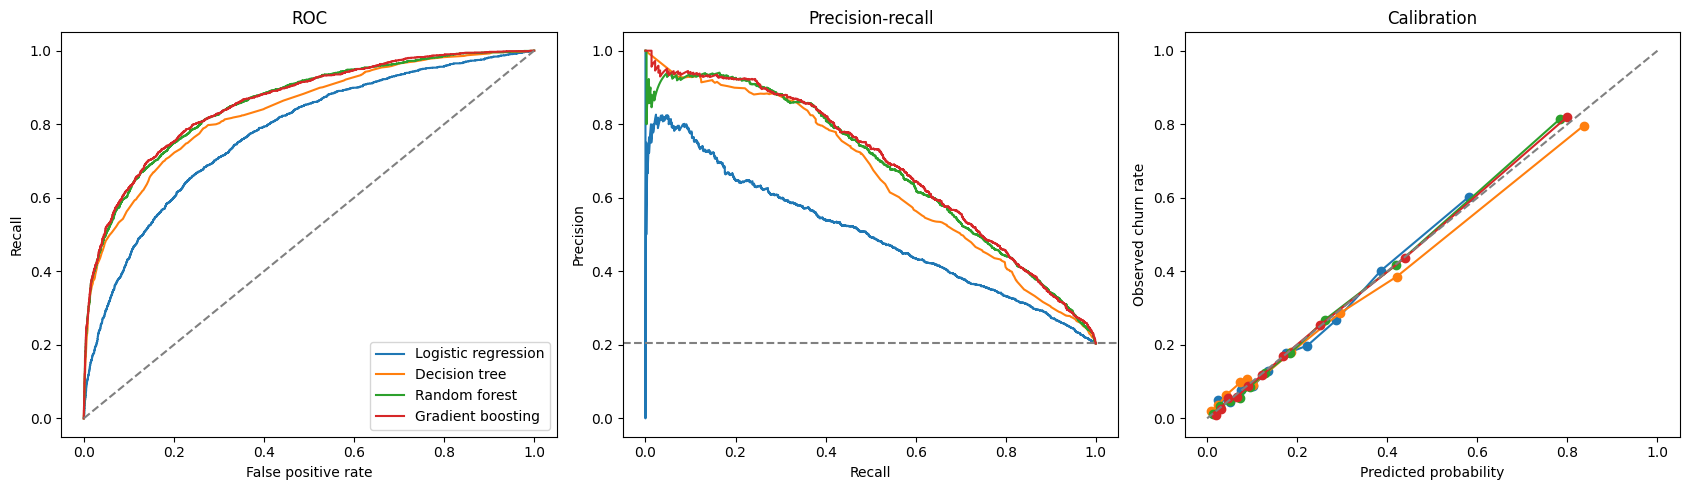

Champion: Gradient boosting
Cost-based threshold c/(e*V): 0.167
Profit-maximising threshold 0.16 | F1-maximising threshold 0.32


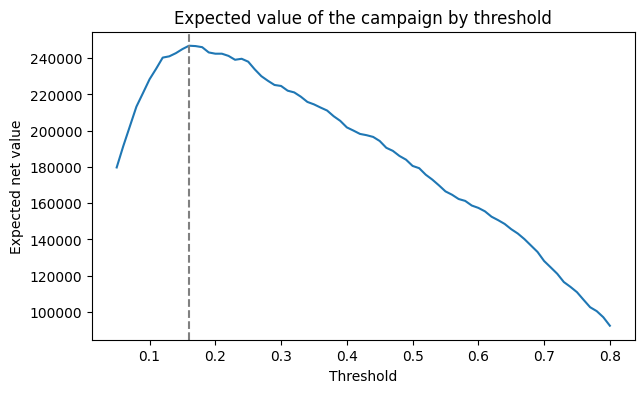

t=0.16 | precision 0.451 | recall 0.801 | false positives 1588
t=0.32 | precision 0.632 | recall 0.614 | false positives 583
t=0.50 | precision 0.753 | recall 0.475 | false positives 254
        customers  churners  churn_rate  cum_capture   lift
decile                                                     
1             800       656       0.820        0.403  4.027
2             800       350       0.438        0.618  2.148
3             800       203       0.254        0.742  1.246
4             800       135       0.169        0.825  0.829
5             800        94       0.118        0.883  0.577
6             800        72       0.090        0.927  0.442
7             800        46       0.058        0.955  0.282
8             800        45       0.056        0.983  0.276
9             800        20       0.025        0.995  0.123
10            799         8       0.010        1.000  0.049
TEST | ROC-AUC 0.865 | avg precision 0.713 | Brier 0.100
TEST at t=0.16 | accuracy 0.756 | pr

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_curve, precision_recall_curve, confusion_matrix)

y_train = y_train.loc[X_train.index]
y = y_train.values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # same folds as before

models = {"Logistic regression": log_reg, "Decision tree": best_tree,
          "Random forest": best_rf, "Gradient boosting": best_gb}

# ---------- 1. Out-of-fold probabilities and the comparison table ----------
oof = {n: cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
       for n, m in models.items()}

rows = {}
for n, p in oof.items():
    pred = (p >= 0.5).astype(int)
    rows[n] = {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred),
               "recall": recall_score(y, pred), "f1": f1_score(y, pred),
               "roc_auc": roc_auc_score(y, p), "avg_precision": average_precision_score(y, p),
               "brier (lower=better)": brier_score_loss(y, p)}
cmp = pd.DataFrame(rows).T
print(cmp.round(3))

# ---------- 2. ROC, precision-recall and calibration curves ----------
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for n, p in oof.items():
    fpr, tpr, _ = roc_curve(y, p);              ax[0].plot(fpr, tpr, label=n)
    pr, rc, _ = precision_recall_curve(y, p);   ax[1].plot(rc, pr, label=n)
    frac, mean_p = calibration_curve(y, p, n_bins=10, strategy="quantile")
    ax[2].plot(mean_p, frac, marker="o", label=n)
ax[0].plot([0, 1], [0, 1], "--", color="grey"); ax[0].set(title="ROC", xlabel="False positive rate", ylabel="Recall")
ax[1].axhline(y.mean(), ls="--", color="grey");  ax[1].set(title="Precision-recall", xlabel="Recall", ylabel="Precision")
ax[2].plot([0, 1], [0, 1], "--", color="grey");  ax[2].set(title="Calibration", xlabel="Predicted probability", ylabel="Observed churn rate")
ax[0].legend(); plt.tight_layout(); plt.show()

# ---------- 3. Champion and threshold (training data only) ----------
champion_name = cmp["roc_auc"].idxmax()      # confirm this against the table and curves
champion, p = models[champion_name], oof[champion_name]
print("Champion:", champion_name)

V, c, e = 1000, 50, 0.30      # PLACEHOLDERS: value of a saved customer, cost of an offer, success rate of an offer
print("Cost-based threshold c/(e*V):", round(c / (e * V), 3))

thr = np.linspace(0.05, 0.80, 76)
profit = np.array([((p >= t) & (y == 1)).sum() * e * V - (p >= t).sum() * c for t in thr])
f1s    = np.array([f1_score(y, (p >= t).astype(int)) for t in thr])
t_profit, t_f1 = thr[profit.argmax()], thr[f1s.argmax()]
print(f"Profit-maximising threshold {t_profit:.2f} | F1-maximising threshold {t_f1:.2f}")

plt.figure(figsize=(7, 4)); plt.plot(thr, profit)
plt.axvline(t_profit, ls="--", color="grey"); plt.xlabel("Threshold"); plt.ylabel("Expected net value")
plt.title("Expected value of the campaign by threshold"); plt.show()

t_final = float(t_profit)     # your decision; document the reasoning
for t in sorted({0.5, round(t_f1, 2), round(t_final, 2)}):
    pred = (p >= t).astype(int)
    print(f"t={t:.2f} | precision {precision_score(y, pred):.3f} | recall {recall_score(y, pred):.3f} "
          f"| false positives {int(((pred == 1) & (y == 0)).sum())}")

# ---------- 4. Lift / gain table ----------
order = np.argsort(-p)
d = pd.DataFrame({"y": y[order]})
d["decile"] = np.repeat(np.arange(1, 11), int(np.ceil(len(d) / 10)))[:len(d)]
g = d.groupby("decile")["y"].agg(customers="size", churners="sum")
g["churn_rate"] = g["churners"] / g["customers"]
g["cum_capture"] = g["churners"].cumsum() / d["y"].sum()
g["lift"] = g["churn_rate"] / d["y"].mean()
print(g.round(3))

# ---------- 5. Final test-set evaluation (champion only, run once) ----------
p_test = champion.predict_proba(X_test)[:, 1]
pred_test = (p_test >= t_final).astype(int)
print(f"TEST | ROC-AUC {roc_auc_score(y_test, p_test):.3f} | avg precision {average_precision_score(y_test, p_test):.3f} "
      f"| Brier {brier_score_loss(y_test, p_test):.3f}")
print(f"TEST at t={t_final:.2f} | accuracy {accuracy_score(y_test, pred_test):.3f} "
      f"| precision {precision_score(y_test, pred_test):.3f} | recall {recall_score(y_test, pred_test):.3f} "
      f"| F1 {f1_score(y_test, pred_test):.3f}")
print(confusion_matrix(y_test, pred_test))     # rows: actual, columns: predicted

## Model Evaluation and Final Test Results

**Method:** All four models were scored on pooled out-of-fold predictions from the same stratified 5-fold CV (training set, 8,000 customers). The best model and threshold were chosen using training data only, and the test set (2,000 customers) was used once, at the end.

### Model comparison (pooled out-of-fold)

| Model | ROC-AUC | Avg precision | Brier (lower = better) |
|---|---|---|---|
| Logistic regression | 0.775 | 0.501 | 0.132 |
| Decision tree | 0.837 | 0.650 | 0.109 |
| Random forest | 0.858 | 0.680 | 0.104 |
| **Gradient boosting** | **0.861** | **0.689** | **0.103** |

- **Gradient boosting** is the champion, but the margin over the random forest is very small (0.003 ROC-AUC, 0.001 Brier). The two are practically tied.
- All three non-linear models clearly beat the logistic baseline on every measure, including the Brier score (0.132 vs 0.103–0.109), so their probability estimates are also more accurate.

### Threshold

- **Cost-based rule:** contact a customer when p > c ÷ (e·V) = **0.167**.
- **Profit-maximising threshold from the out-of-fold predictions:** **0.16**, which agrees closely with the rule. **F1-maximising threshold:** 0.32.
- These costs are **placeholder assumptions** (value of a saved customer, offer cost, offer success rate), so the

- These costs are **placeholder assumptions** (value of a saved customer, offer cost, offer success rate), so the threshold must be revisited with realistic figures.

| Threshold | Precision | Recall | False positives (training) |
|---|---|---|---|
| 0.16 (profit-maximising, chosen) | 0.451 | 0.801 | 1,588 |
| 0.32 (F1-maximising) | 0.632 | 0.614 | 583 |
| 0.50 (default) | 0.753 | 0.475 | 254 |

Lowering the threshold catches many more churners (recall 0.80 vs 0.48) at the price of many more wasted offers. At 0.16 about 36% of customers are flagged.

### Lift and gain (training, out-of-fold)

- The **riskiest 10%** of customers have a churn rate of 82% (lift 4.0) and contain **40%** of all churners.
- The riskiest **20%** capture **62%** of churners, the top 30% capture 74%, and the top 50% capture 88%.
- The least risky decile has a churn rate of 1% (lift 0.05), so low-risk customers can be left out of campaigns.

### Final test-set result (gradient boosting, threshold 0.16, evaluated once)

| ROC-AUC | Avg precision | Brier | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|---|
| 0.865 | 0.713 | 0.100 | 0.756 | 0.446 | 0.816 | 0.577 |

Confusion matrix (rows: actual, columns: predicted):

| | Predicted stay | Predicted churn |
|---|---|---|
| **Actual stay** | 1,181 | 412 |
| **Actual churn** | 75 | 332 |

- The model catches 332 of 407 real churners (81.6%) and raises 412 false alarms. About 37% of customers are flagged.
- **Test results match the cross-validated ones** (ROC-AUC 0.865 vs 0.861, precision 0.446 vs 0.451, recall 0.816 vs 0.801), so there is no sign of overfitting from the tuning.
- Accuracy falls to 0.756 by design: flagging more customers produces more false alarms, so accuracy is not the right measure for this threshold.

### Conclusions

- Gradient boosting ranks customers well (test ROC-AUC 0.865) and its probabilities are informative (Brier 0.100).
- At the cost-based threshold the model reaches about 80% recall, and the riskiest 20% of customers contain roughly 62% of churners, which supports a targeted campaign.
- The close agreement between the cost-based and profit-maximising thresholds suggests the probabilities are reasonably calibrated.

### Caveats

- The threshold depends on the placeholder costs. Replace them with realistic values and check how sensitive the choice is, since the profit curve may be flat near its peak.
- Using a single value V for every customer is a simplification. In practice, the value of a saved customer varies with balance and products.
- The choice of gradient boosting over the random forest rests on a tiny margin, and the forest would be an acceptable alternative.
- The calibration curves should be reviewed visually before the scores are presented as literal probabilities.
- The test set has now been used, so no further changes to the model, features or threshold should be made based on it.

Baseline test ROC-AUC: 0.865
                                mean_drop     std
Age                                0.1191  0.0084
NumOfProducts                      0.1072  0.0098
Geography                          0.0192  0.0022
Balance                            0.0169  0.0028
Engagement_Product_Interaction     0.0086  0.0024
IsActiveMember                     0.0084  0.0026
Gender                             0.0081  0.0017
Balance_to_Salary                  0.0053  0.0015
CreditScore                        0.0018  0.0009
Tenure                             0.0000  0.0001
HasCrCard                         -0.0001  0.0001
Product_Density                   -0.0006  0.0006
Age_Tenure_Ratio                  -0.0007  0.0007
Age_Tenure_Interaction            -0.0011  0.0005
EstimatedSalary                   -0.0023  0.0013
                          mean_drop     std
Engagement & product use     0.1540  0.0109
Age & tenure                 0.1220  0.0095
Balance & salary             0.0241  0.

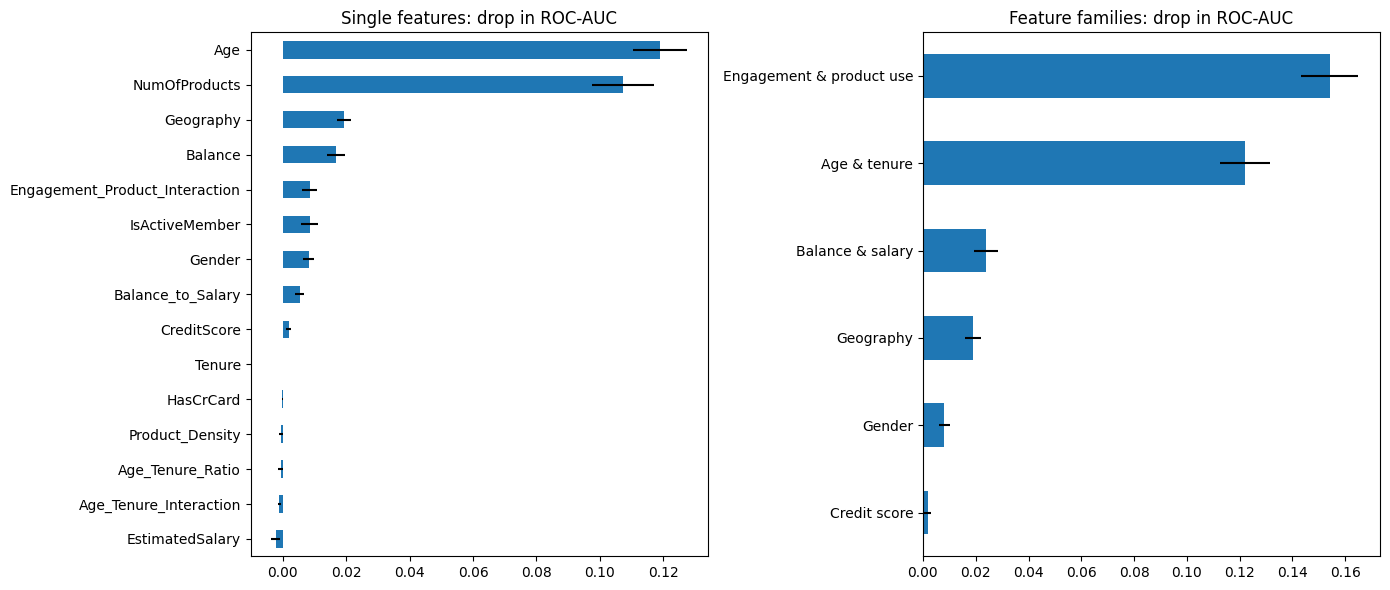

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

feat_cols = cat_cols + num_cols            # the columns the champion pipeline reads (defined in the tree/forest cells)
base_auc = roc_auc_score(y_test, champion.predict_proba(X_test[feat_cols])[:, 1])
print("Baseline test ROC-AUC:", round(base_auc, 3))

# (a) One feature at a time
pi = permutation_importance(champion, X_test[feat_cols], y_test, scoring="roc_auc",
                            n_repeats=20, random_state=42, n_jobs=1)
single = pd.DataFrame({"mean_drop": pi.importances_mean, "std": pi.importances_std},
                      index=feat_cols).sort_values("mean_drop", ascending=False)
print(single.round(4))

# (b) Feature families shuffled together (each feature belongs to exactly one family)
families = {
    "Engagement & product use": ["IsActiveMember", "NumOfProducts", "HasCrCard",
                                 "Product_Density", "Engagement_Product_Interaction"],
    "Age & tenure":             ["Age", "Tenure", "Age_Tenure_Ratio", "Age_Tenure_Interaction"],
    "Balance & salary":         ["Balance", "EstimatedSalary", "Balance_to_Salary"],
    "Geography":                ["Geography"],
    "Gender":                   ["Gender"],
    "Credit score":             ["CreditScore"],
}
covered = [c for cols in families.values() for c in cols]
assert sorted(covered) == sorted(feat_cols), set(feat_cols) ^ set(covered)   # every feature exactly once

rng = np.random.default_rng(42)
rows = {}
for fam, cols in families.items():
    drops = []
    for _ in range(20):
        perm = rng.permutation(len(X_test))
        Xp = X_test[feat_cols].copy()
        for col in cols:
            Xp[col] = X_test[col].values[perm]       # same row shuffle for every column in the family
        drops.append(base_auc - roc_auc_score(y_test, champion.predict_proba(Xp)[:, 1]))
    rows[fam] = {"mean_drop": np.mean(drops), "std": np.std(drops)}
family = pd.DataFrame(rows).T.sort_values("mean_drop", ascending=False)
print(family.round(4))

# Plots
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
single["mean_drop"].sort_values().plot.barh(ax=ax[0], xerr=single["std"].reindex(single["mean_drop"].sort_values().index),
                                            title="Single features: drop in ROC-AUC")
family["mean_drop"].sort_values().plot.barh(ax=ax[1], xerr=family["std"].reindex(family["mean_drop"].sort_values().index),
                                            title="Feature families: drop in ROC-AUC")
plt.tight_layout(); plt.show()

## Model Explainability: Permutation Importance

**Method:** For the champion model (gradient boosting, baseline test ROC-AUC **0.865**), each feature, or each family of related features, was shuffled across customers 20 times. Importance is the average drop in ROC-AUC, so a larger drop means the model relies on the feature more. Family-level shuffling uses one shared row shuffle for all features in the family, so relationships inside the family are preserved. The model and threshold were fixed beforehand, so this analysis changed no decision.

### Single-feature results

| Tier | Feature | Mean drop in ROC-AUC (± std) |
|---|---|---|
| Dominant | Age | 0.119 ± 0.008 |
| Dominant | NumOfProducts | 0.107 ± 0.010 |
| Secondary | Geography | 0.019 ± 0.002 |
| Secondary | Balance | 0.017 ± 0.003 |
| Minor | Engagement_Product_Interaction | 0.009 ± 0.002 |
| Minor | IsActiveMember | 0.008 ± 0.003 |
| Minor | Gender | 0.008 ± 0.002 |
| Minor | Balance_to_Salary | 0.005 ± 0.002 |
| Negligible | CreditScore | 0.002 ± 0.001 |
| None | Tenure, HasCrCard, Product_Density, Age_Tenure_Ratio, Age_Tenure_Interaction, EstimatedSalary | about 0 or slightly negative |

### Feature-family results

| Family | Mean drop in ROC-AUC (± std) |
|---|---|
| Engagement & product use (IsActiveMember, NumOfProducts, HasCrCard, Product_Density, Engagement_Product_Interaction) | **0.154 ± 0.011** |
| Age & tenure (Age, Tenure, Age_Tenure_Ratio, Age_Tenure_Interaction) | 0.122 ± 0.010 |
| Balance & salary (Balance, EstimatedSalary, Balance_to_Salary) | 0.024 ± 0.005 |
| Geography | 0.019 ± 0.003 |
| Gender | 0.008 ± 0.002 |
| Credit score | 0.002 ± 0.001 |

### Key findings

- **Two features carry most of the model's predictive power.** Shuffling Age lowers the ROC-AUC from 0.865 to about 0.746, and shuffling NumOfProducts lowers it to about 0.758. Every other single feature causes a drop of 0.02 or less.
- **Second tier:** Geography (0.019) and Balance (0.017) matter, but about six times less than Age or NumOfProducts. Gender (0.008) has a small effect, and CreditScore (0.002) is barely distinguishable from zero.
- **Engagement & product use is the most important concept.** Shuffling the whole family lowers the ROC-AUC to about 0.71 (drop 0.154), more than any single member (NumOfProducts alone: 0.107). The extra 0.047 comes from the activity-related features (IsActiveMember, Engagement_Product_Interaction, Product_Density), which individually look small because they overlap and compensate for each other when only one is shuffled.
- **Product count is the main part of that family.** Activity-related features add a smaller contribution on top of it.
- **Age & tenure is almost entirely Age.** The family drop (0.122) is barely above Age alone (0.119), and Tenure and both Age-Tenure features contribute nothing. Time with the bank adds no information beyond age.
- **Balance & salary adds little:** the family drop is 0.024, only slightly more than Balance alone

- **Engineered features:** Engagement_Product_Interaction (0.009) and Balance_to_Salary (0.005) make small positive contributions. Product_Density, Age_Tenure_Ratio and Age_Tenure_Interaction show no reliance. This does not mean they hold no information: each is built from raw columns that remain in the data, so the model can get the same information from them.

### Comparison with impurity-based importance (gradient boosting)

- **Agreement:** both methods rank Age and NumOfProducts first and second.
- **Disagreement:** impurity-based importance gave sizeable shares to Engagement_Product_Interaction (0.100), Balance_to_Salary (0.036), EstimatedSalary (0.035) and CreditScore (0.033), but permutation importance shows these contribute very little (0.009, 0.005, about 0 and 0.002).
- **Why:** impurity-based importance favours features with many distinct values (continuous variables), so it overstates the weak continuous features. Permutation importance on held-out data measures actual predictive reliance and is the more trustworthy ranking.

### Provisional reading against the project's thesis

- The guide's framing is that engagement and product use matter more than demographics. The evidence supports this partly: the engagement and product use family has the largest drop (0.154), ahead of age (0.122).
- Age is a close second and clearly not minor, so demographics are not irrelevant. Geography (0.019) and Gender (0.008) are much smaller.
- This comparison is refined in the summary of key churn drivers. Age sits in a family with tenure, so the demographic side is not cleanly separated, and the engagement family is dominated by product count rather than activity.

### Business interpretation

- Risk is driven mainly by **how many products a customer holds** and **how old the customer is**. Retention effort should be organised around product-holding patterns and life-stage segments before anything else.
- Customer activity (IsActiveMember) matters, but its effect is shared with product count, so it should be considered together with products, not separately.
- Geography is a meaningful but secondary lever, which suggests market-specific retention work, for example in Germany, where churn is known to be higher in this dataset.
- Credit score, salary and credit card ownership play little role, so campaigns do not need to target on them.

### Caveats

- Permutation importance shows **how much** the model relies on a feature, not **in which direction**. Direction is covered by the SHAP analysis and the partial dependence plots.
- Shuffling can create unrealistic combinations (for example a very young customer with a long tenure), especially for correlated features. The family-level shuffling reduces this but doesn't remove it.
- Single-feature drops understate the importance of features that overlap with others, such as the engagement and product features, so the family results should be used for those.
- Drops below roughly two standard deviations (CreditScore, and the slightly negative values for EstimatedSalary and the Age-Tenure features) are treated as no evidence of reliance. A slightly negative drop is noise-level and does not mean the feature hurts the model.
- The standard deviations show only shuffling noise. They do not capture sampling uncertainty from the finite test set (2,000 customers, 407 churners).
- Family composition is a modelling choice: HasCrCard was grouped with product use, and Age was grouped with tenure.

Base value (average model output): -1.8865
SHAP matrix shape: (2000, 18)


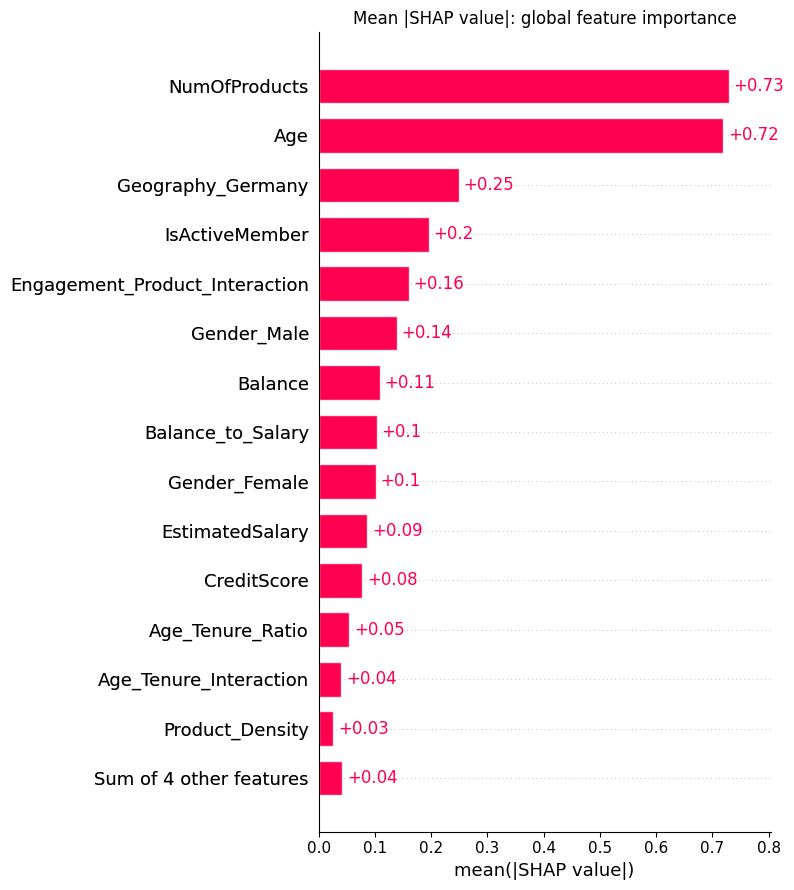

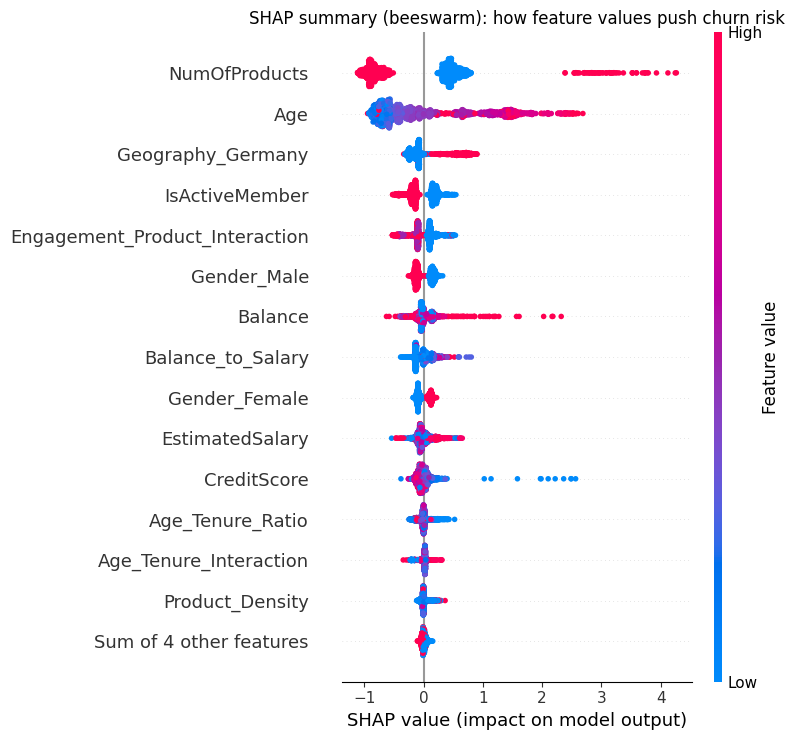

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(



Explaining customer at index 2154 | predicted churn probability = 0.978


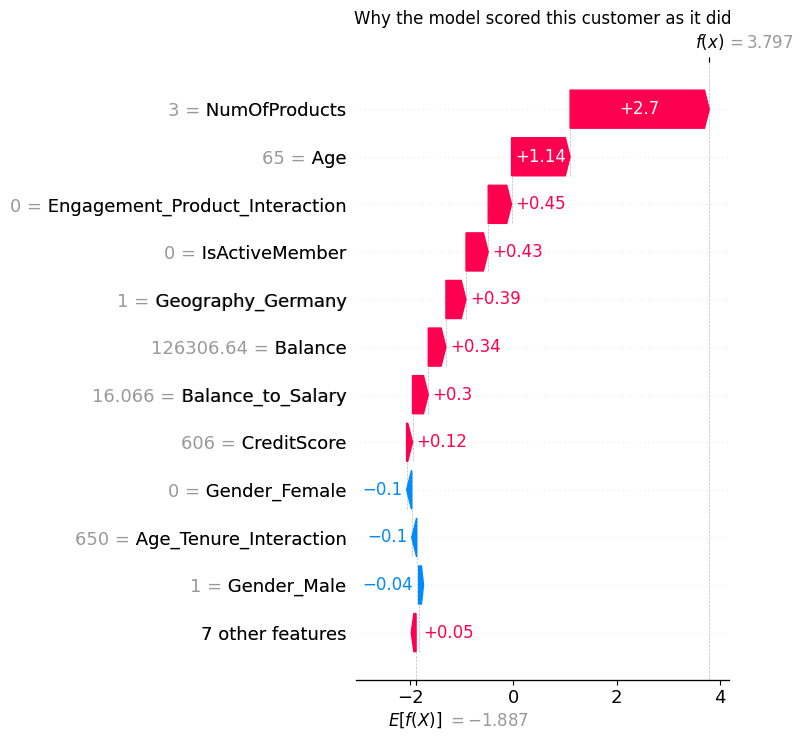

                          feature        value  shap_value
0                   NumOfProducts       3.0000      2.6973
1                             Age      65.0000      1.1351
2  Engagement_Product_Interaction       0.0000      0.4525
3                  IsActiveMember       0.0000      0.4301
4               Geography_Germany       1.0000      0.3893
5                         Balance  126306.6400      0.3425
6               Balance_to_Salary      16.0661      0.3047
7                     CreditScore     606.0000      0.1154
8                   Gender_Female       0.0000     -0.0993
9          Age_Tenure_Interaction     650.0000     -0.0954


In [ ]:
# ============================================================
# SHAP ANALYSIS: summary plots + one individual customer
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# ---------------- CONFIG: edit these to match your notebook ----------------
champion_pipe = best_gb      # fitted champion pipeline (tree model, unscaled)
X_explain_raw = X_train              # TRAINING data, raw columns as fed to the pipeline
SAMPLE_N      = 2000                 # SHAP on a sample keeps it fast; the pattern is stable
RANDOM_STATE  = 42
# ---------------------------------------------------------------------------

# 1) Split the pipeline into (preprocessing) and (tree model)
#    SHAP explains the tree, so it must see the same columns the tree sees.
if hasattr(champion_pipe, "named_steps"):
    preprocessor = champion_pipe[:-1]
    model        = champion_pipe[-1]
else:                                # champion is a bare model with no pipeline
    preprocessor = None
    model        = champion_pipe

# 2) Sample rows and transform them, keeping feature names
X_sample_raw = X_explain_raw.sample(min(SAMPLE_N, len(X_explain_raw)),
                                    random_state=RANDOM_STATE)

if preprocessor is not None:
    X_sample = preprocessor.transform(X_sample_raw)
    try:
        feature_names = preprocessor.get_feature_names_out()
        feature_names = [n.split("__")[-1] for n in feature_names]  # drop "num__", "cat__" prefixes
    except Exception:
        feature_names = list(X_sample_raw.columns)
    X_sample = pd.DataFrame(X_sample, columns=feature_names, index=X_sample_raw.index)
else:
    X_sample = X_sample_raw.copy()

# 3) Build the explainer and compute SHAP values
explainer   = shap.TreeExplainer(model)
shap_values = explainer(X_sample)    # returns a shap.Explanation object

# Some models (e.g. random forest) return one slice per class: keep the churn class (1)
if shap_values.values.ndim == 3:
    shap_values = shap_values[:, :, 1]

print("Base value (average model output):", np.round(np.ravel(shap_values.base_values)[0], 4))
print("SHAP matrix shape:", shap_values.values.shape)

# 4) SUMMARY PLOT A: global importance (mean |SHAP| per feature)
plt.figure()
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("Mean |SHAP value|: global feature importance")
plt.tight_layout()
plt.show()

# 5) SUMMARY PLOT B: beeswarm (direction + size of each feature's effect)
plt.figure()
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP summary (beeswarm): how feature values push churn risk")
plt.tight_layout()
plt.show()

# 6) INDIVIDUAL CUSTOMER: pick the highest-risk customer in the sample
#    (change `pos` to explain any other row, e.g. pos = 0)
proba = model.predict_proba(X_sample)[:, 1]
pos   = int(np.argmax(proba))
print(f"\nExplaining customer at index {X_sample.index[pos]} | predicted churn probability = {proba[pos]:.3f}")

plt.figure()
shap.plots.waterfall(shap_values[pos], max_display=12, show=False)
plt.title("Why the model scored this customer as it did")
plt.tight_layout()
plt.show()

# 7) The same explanation as a table (easy to quote in the write-up)
contrib = (pd.DataFrame({
              "feature":     X_sample.columns,
              "value":       X_sample.iloc[pos].values,
              "shap_value":  shap_values.values[pos]})
           .assign(abs_shap=lambda d: d.shap_value.abs())
           .sort_values("abs_shap", ascending=False)
           .drop(columns="abs_shap")
           .head(10)
           .reset_index(drop=True))
print(contrib.round(4))

In [ ]:
# Paste your ORIGINAL feature-engineering lines inside this function
# (only the engineered columns; leave scaling/transforms to the pipeline
#  unless you created the log columns by hand outside it)
def recompute_engineered(df):
    d = df.copy()
    elipson = 1e-15
    d['Balance_to_Salary'] = d['Balance']/(d['EstimatedSalary'] + elipson)
    d['Product_Density'] = d['NumOfProducts']/(d['Tenure'] + 1)
    d['Age_Tenure_Ratio'] = d['Tenure']/(d['Age'])
    d['Age_Tenure_Interaction'] = d['Age']*d['Tenure']
    d['Engagement_Product_Interaction'] = d['IsActiveMember'] * d['NumOfProducts']
    return d

# Check: rebuilding from raw inputs must reproduce the columns already in X_train
engineered_cols = ["Balance_to_Salary", "Product_Density", "Age_Tenure_Ratio",
                   "Age_Tenure_Interaction", "Engagement_Product_Interaction"]
rebuilt = recompute_engineered(X_train.drop(columns=engineered_cols))
print(np.allclose(rebuilt[engineered_cols], X_train[engineered_cols]))   # must be True

True


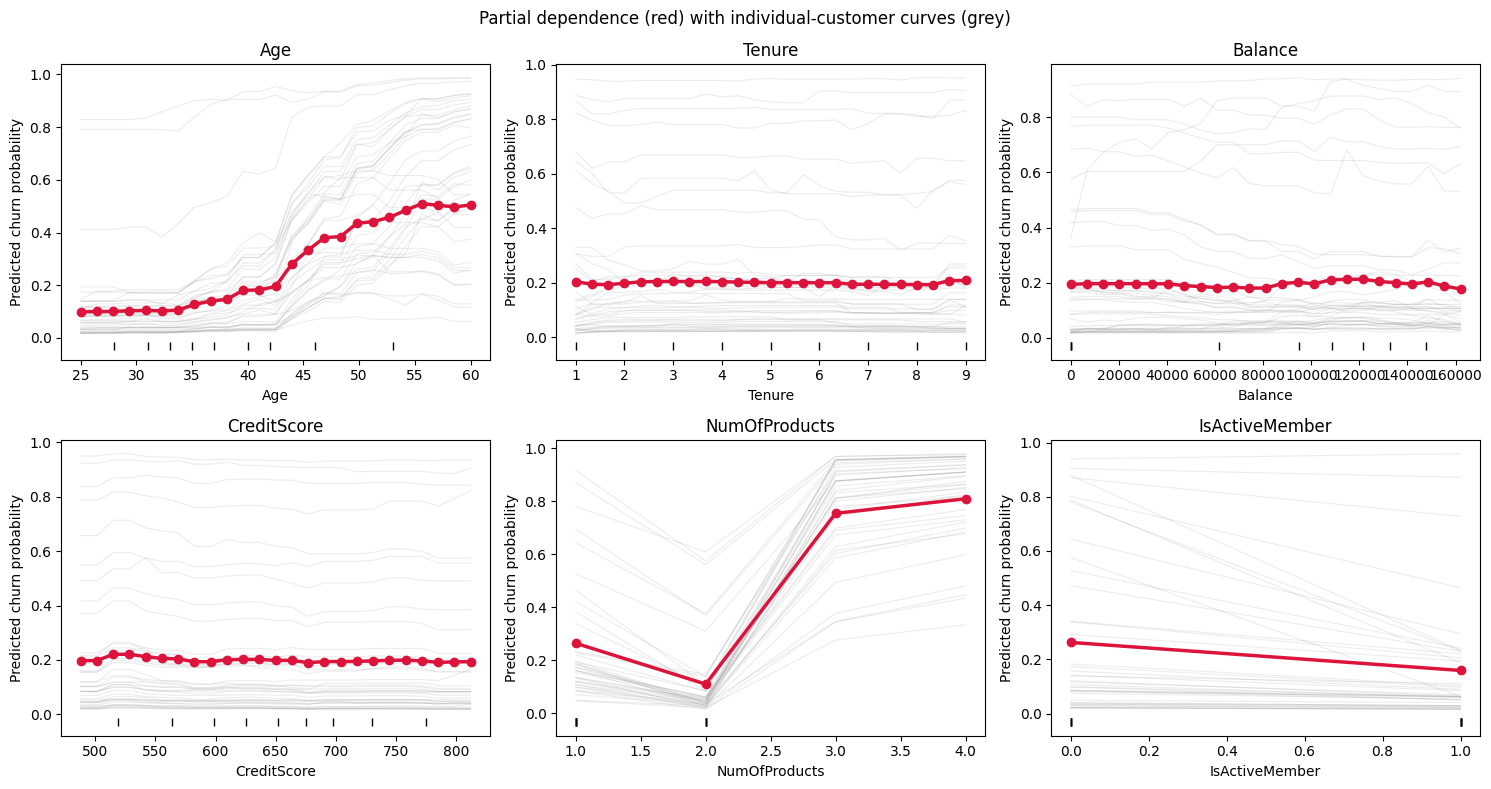

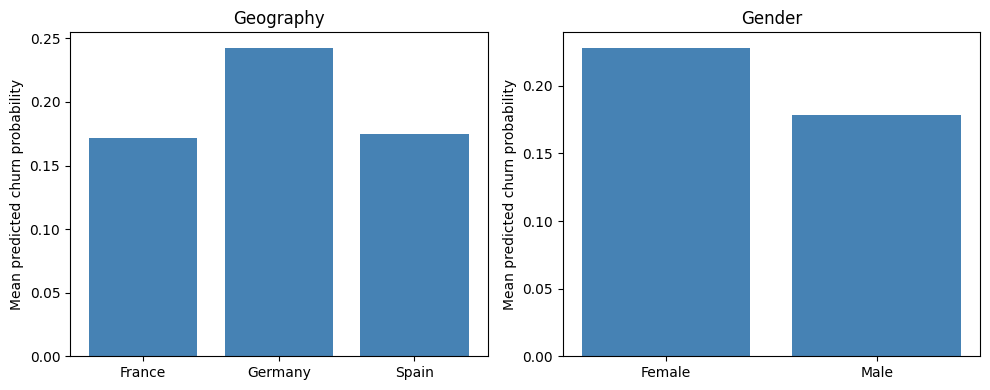

In [ ]:
# ============================================================
# PARTIAL DEPENDENCE (+ ICE) with engineered features recomputed
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- CONFIG: edit these to match your notebook ----------------
champion_pipe = best_gb              # fitted champion pipeline (takes raw columns)
X_pdp_raw     = X_train              # training data, same columns the pipeline was fitted on
SAMPLE_N      = 2000
N_ICE_LINES   = 40                   # faint individual-customer lines drawn behind the average
RANDOM_STATE  = 42

continuous_feats = ["Age", "Tenure", "Balance", "CreditScore"]
discrete_feats   = ["NumOfProducts", "IsActiveMember"]   # few distinct values: one point per value
category_feats   = ["Geography", "Gender"]               # shown as bars

def recompute_engineered(df):
    d = df.copy()
    elipson = 1e-15
    d['Balance_to_Salary'] = d['Balance']/(d['EstimatedSalary'] + elipson)
    d['Product_Density'] = d['NumOfProducts']/(d['Tenure'] + 1)
    d['Age_Tenure_Ratio'] = d['Tenure']/(d['Age'])
    d['Age_Tenure_Interaction'] = d['Age']*d['Tenure']
    d['Engagement_Product_Interaction'] = d['IsActiveMember'] * d['NumOfProducts']
    return d
# ---------------------------------------------------------------------------

X_s = X_pdp_raw.sample(min(SAMPLE_N, len(X_pdp_raw)), random_state=RANDOM_STATE)
rng = np.random.RandomState(RANDOM_STATE)
ice_rows = rng.choice(len(X_s), size=min(N_ICE_LINES, len(X_s)), replace=False)

def predict_over_grid(feature, grid):
    """Return matrix (rows x grid points) of predicted churn probability."""
    out = np.empty((len(X_s), len(grid)))
    for j, v in enumerate(grid):
        d = X_s.copy()
        d[feature] = v                      # force every customer to this value
        d = recompute_engineered(d)         # keep derived features consistent
        out[:, j] = champion_pipe.predict_proba(d)[:, 1]
    return out

# ---- Numeric features: PDP line + ICE lines + rug of observed deciles ----
num_feats = continuous_feats + discrete_feats
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), num_feats):
    if f in discrete_feats:
        grid = np.sort(X_s[f].unique())
    else:
        grid = np.linspace(X_s[f].quantile(0.05), X_s[f].quantile(0.95), 25)
    P = predict_over_grid(f, grid)
    ax.plot(grid, P[ice_rows].T, color="grey", alpha=0.15, lw=0.8)      # ICE
    ax.plot(grid, P.mean(axis=0), color="crimson", lw=2.5, marker="o")  # PDP
    ax.plot(np.quantile(X_s[f], np.linspace(0.1, 0.9, 9)),
            np.full(9, ax.get_ylim()[0]), "|", color="black")           # data deciles
    ax.set_title(f); ax.set_xlabel(f); ax.set_ylabel("Predicted churn probability")
plt.suptitle("Partial dependence (red) with individual-customer curves (grey)")
plt.tight_layout(); plt.show()

# ---- Categorical features: average predicted probability per category ----
fig, axes = plt.subplots(1, len(category_feats), figsize=(10, 4))
for ax, f in zip(np.atleast_1d(axes), category_feats):
    cats = sorted(X_s[f].unique())
    P = predict_over_grid(f, cats)
    ax.bar([str(c) for c in cats], P.mean(axis=0), color="steelblue")
    ax.set_title(f); ax.set_ylabel("Mean predicted churn probability")
plt.tight_layout(); plt.show()

In [ ]:
# ============================================================
# TARGET AND OUTPUT DEFINITION: probability + flag, saved pipeline
# ============================================================
import joblib
import numpy as np
import pandas as pd
import sklearn

# ---------------- CONFIG: edit these to match your notebook ----------------
champion_pipe = best_gb        # fitted champion pipeline (raw columns in, probability out)
threshold     = 0.16       # decided earlier from TRAINING out-of-fold predictions
feature_cols  = list(X_train.columns)  # exact columns, in order, that the pipeline was fitted on
SAVE_PATH     = "churn_model.joblib"
# ---------------------------------------------------------------------------

def score_customers(df, pipe=champion_pipe, thr=threshold):
    """Target definition: Exited = 1 means the customer left.
    Output: churn probability (0-1) and a flag = 1 when probability >= threshold."""
    missing = [c for c in feature_cols if c not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")
    proba = pipe.predict_proba(df[feature_cols])[:, 1]
    return pd.DataFrame({"churn_probability": proba,
                         "churn_flag": (proba >= thr).astype(int)},
                        index=df.index)

# Save everything needed to reproduce a score: pipeline, threshold, expected columns
artifact = {
    "pipeline":     champion_pipe,
    "threshold":    float(threshold),
    "feature_cols": feature_cols,
    "target":       "Exited (1 = churned)",
    "sklearn_version": sklearn.__version__,
}
joblib.dump(artifact, SAVE_PATH)

# Sanity check on a TRAINING sample (the test set stays reserved for its single evaluation):
# the reloaded artifact must reproduce the in-memory scores exactly
loaded  = joblib.load(SAVE_PATH)
sample  = X_train.sample(500, random_state=42)
before  = score_customers(sample)
after   = score_customers(sample, pipe=loaded["pipeline"], thr=loaded["threshold"])
assert np.allclose(before["churn_probability"], after["churn_probability"]), "Reloaded model differs!"
assert (before["churn_flag"] == after["churn_flag"]).all()
print("Saved to", SAVE_PATH, "| reload check passed")
print(f"Flag rate in sample: {before['churn_flag'].mean():.1%} at threshold {threshold:.3f}")
print(before.head())

Saved to churn_model.joblib | reload check passed
Flag rate in sample: 35.2% at threshold 0.160
      churn_probability  churn_flag
7853           0.726197           1
8446           0.038032           0
4034           0.247022           1
4515           0.034870           0
8737           0.061017           0


Customer index 2154
      Age  Tenure    Balance  NumOfProducts  IsActiveMember
2154   65      10  126306.64              3               0
                  scenario  churn_probability  churn_flag  change_vs_baseline
                  Baseline              0.978         1.0               0.000
 Activate inactive members              0.905         1.0              -0.073
     +1 product (cap at 4)              0.980         1.0               0.002
      Activate + 1 product              0.914         1.0              -0.064
 Sensitivity: balance -20%              0.949         1.0              -0.029
Sensitivity: 5 years older              0.940         1.0              -0.038

Currently flagged customers in sample: 706
Baseline mean probability among flagged: 0.453
                  scenario  mean_probability  change_vs_baseline  share_still_flagged
 Activate inactive members             0.347              -0.106                0.819
     +1 product (cap at 4)             0.364       

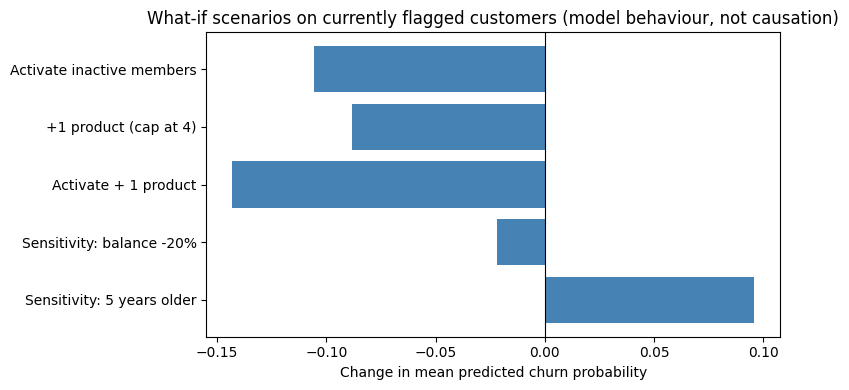

In [ ]:
# ============================================================
# WHAT-IF SCENARIO ANALYSIS
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- CONFIG: edit these to match your notebook ----------------
# Needs: score_customers(), recompute_engineered(), threshold, feature_cols (from earlier blocks)
X_whatif_raw = X_train        # training data; the test set stays reserved for its single evaluation
RANDOM_STATE = 42
# ---------------------------------------------------------------------------

def apply_scenario(df, changes):
    """Apply a scenario to every row, then rebuild the derived features.
    `changes` maps column -> function(series) -> new series."""
    d = df.copy()
    for col, fn in changes.items():
        d[col] = fn(d[col])
    return recompute_engineered(d)

# Scenario definitions. Levers the bank could influence come first; the last two are
# pure sensitivity checks (the bank cannot change age or tenure).
scenarios = {
    "Activate inactive members":      {"IsActiveMember": lambda s: np.ones_like(s)},
    "+1 product (cap at 4)":          {"NumOfProducts": lambda s: np.minimum(s + 1, 4)},
    "Activate + 1 product":           {"IsActiveMember": lambda s: np.ones_like(s),
                                       "NumOfProducts":  lambda s: np.minimum(s + 1, 4)},
    "Sensitivity: balance -20%":      {"Balance": lambda s: s * 0.8},
    "Sensitivity: 5 years older":     {"Age": lambda s: s + 5},
}

# ------------------------------------------------------------------
# PART 1: ONE CUSTOMER, scenario by scenario
# ------------------------------------------------------------------
# Default: the highest-risk customer in a sample (change `row` to pick someone else)
sample = X_whatif_raw.sample(min(2000, len(X_whatif_raw)), random_state=RANDOM_STATE)
base_scores = score_customers(sample)
row = base_scores["churn_probability"].idxmax()
cust = sample.loc[[row]]

rows = [{"scenario": "Baseline",
         **score_customers(cust).iloc[0].to_dict()}]
for name, ch in scenarios.items():
    s = score_customers(apply_scenario(cust, ch)).iloc[0].to_dict()
    rows.append({"scenario": name, **s})

one = pd.DataFrame(rows)
one["change_vs_baseline"] = one["churn_probability"] - one.loc[0, "churn_probability"]
print(f"Customer index {row}")
print(cust[["Age", "Tenure", "Balance", "NumOfProducts", "IsActiveMember"]].to_string())
print(one.round(3).to_string(index=False))

# ------------------------------------------------------------------
# PART 2: SEGMENT LEVEL, effect on all customers currently flagged as high risk
# ------------------------------------------------------------------
flagged = sample[base_scores["churn_flag"] == 1]
print(f"\nCurrently flagged customers in sample: {len(flagged)}")

seg_rows = []
base_mean = score_customers(flagged)["churn_probability"].mean()
for name, ch in scenarios.items():
    new = score_customers(apply_scenario(flagged, ch))
    seg_rows.append({
        "scenario": name,
        "mean_probability": new["churn_probability"].mean(),
        "change_vs_baseline": new["churn_probability"].mean() - base_mean,
        "share_still_flagged": new["churn_flag"].mean(),
    })
seg = pd.DataFrame(seg_rows)
print(f"Baseline mean probability among flagged: {base_mean:.3f}")
print(seg.round(3).to_string(index=False))

# Chart: average change in churn probability by scenario (flagged segment)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(seg["scenario"][::-1], seg["change_vs_baseline"][::-1], color="steelblue")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Change in mean predicted churn probability")
ax.set_title("What-if scenarios on currently flagged customers (model behaviour, not causation)")
plt.tight_layout(); plt.show()

Customer index 2154
      Age  Tenure    Balance  NumOfProducts  IsActiveMember
2154   65      10  126306.64              3               0
                  scenario  churn_probability  churn_flag  change_vs_baseline
                  Baseline              0.978         1.0               0.000
 Activate inactive members              0.905         1.0              -0.073
     +1 product (cap at 4)              0.980         1.0               0.002
      Activate + 1 product              0.914         1.0              -0.064
 Sensitivity: balance -20%              0.949         1.0              -0.029
Sensitivity: 5 years older              0.940         1.0              -0.038

Currently flagged customers in sample: 706
Baseline mean probability among flagged: 0.453
                  scenario  mean_probability  change_vs_baseline  share_still_flagged
 Activate inactive members             0.347              -0.106                0.819
     +1 product (cap at 4)             0.364       

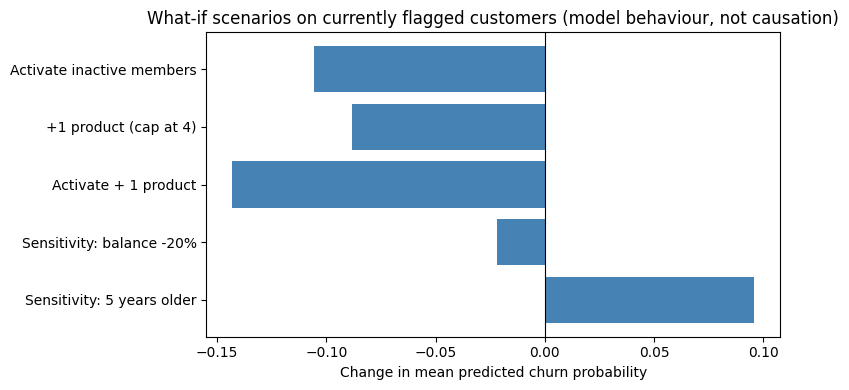

In [ ]:
# ============================================================
# WHAT-IF SCENARIO ANALYSIS
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- CONFIG: edit these to match your notebook ----------------
# Needs: score_customers(), recompute_engineered(), threshold, feature_cols (from earlier blocks)
X_whatif_raw = X_train        # training data; the test set stays reserved for its single evaluation
RANDOM_STATE = 42
# ---------------------------------------------------------------------------

def apply_scenario(df, changes):
    """Apply a scenario to every row, then rebuild the derived features.
    `changes` maps column -> function(series) -> new series."""
    d = df.copy()
    for col, fn in changes.items():
        d[col] = fn(d[col])
    return recompute_engineered(d)

# Scenario definitions. Levers the bank could influence come first; the last two are
# pure sensitivity checks (the bank cannot change age or tenure).
scenarios = {
    "Activate inactive members":      {"IsActiveMember": lambda s: np.ones_like(s)},
    "+1 product (cap at 4)":          {"NumOfProducts": lambda s: np.minimum(s + 1, 4)},
    "Activate + 1 product":           {"IsActiveMember": lambda s: np.ones_like(s),
                                       "NumOfProducts":  lambda s: np.minimum(s + 1, 4)},
    "Sensitivity: balance -20%":      {"Balance": lambda s: s * 0.8},
    "Sensitivity: 5 years older":     {"Age": lambda s: s + 5},
}

# ------------------------------------------------------------------
# PART 1: ONE CUSTOMER, scenario by scenario
# ------------------------------------------------------------------
# Default: the highest-risk customer in a sample (change `row` to pick someone else)
sample = X_whatif_raw.sample(min(2000, len(X_whatif_raw)), random_state=RANDOM_STATE)
base_scores = score_customers(sample)
row = base_scores["churn_probability"].idxmax()
cust = sample.loc[[row]]

rows = [{"scenario": "Baseline",
         **score_customers(cust).iloc[0].to_dict()}]
for name, ch in scenarios.items():
    s = score_customers(apply_scenario(cust, ch)).iloc[0].to_dict()
    rows.append({"scenario": name, **s})

one = pd.DataFrame(rows)
one["change_vs_baseline"] = one["churn_probability"] - one.loc[0, "churn_probability"]
print(f"Customer index {row}")
print(cust[["Age", "Tenure", "Balance", "NumOfProducts", "IsActiveMember"]].to_string())
print(one.round(3).to_string(index=False))

# ------------------------------------------------------------------
# PART 2: SEGMENT LEVEL, effect on all customers currently flagged as high risk
# ------------------------------------------------------------------
flagged = sample[base_scores["churn_flag"] == 1]
print(f"\nCurrently flagged customers in sample: {len(flagged)}")

seg_rows = []
base_mean = score_customers(flagged)["churn_probability"].mean()
for name, ch in scenarios.items():
    new = score_customers(apply_scenario(flagged, ch))
    seg_rows.append({
        "scenario": name,
        "mean_probability": new["churn_probability"].mean(),
        "change_vs_baseline": new["churn_probability"].mean() - base_mean,
        "share_still_flagged": new["churn_flag"].mean(),
    })
seg = pd.DataFrame(seg_rows)
print(f"Baseline mean probability among flagged: {base_mean:.3f}")
print(seg.round(3).to_string(index=False))

# Chart: average change in churn probability by scenario (flagged segment)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(seg["scenario"][::-1], seg["change_vs_baseline"][::-1], color="steelblue")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Change in mean predicted churn probability")
ax.set_title("What-if scenarios on currently flagged customers (model behaviour, not causation)")
plt.tight_layout(); plt.show()

In [ ]:
# Model artifact (pipeline + threshold + column list) was saved earlier as churn_model.joblib.
# The app also needs two small tables:
train_scores = score_customers(X_train)[["churn_probability"]]
train_scores.to_csv("train_scores.csv", index=True) # Set index=True if the app needs customer IDs as index, or False otherwise

# Fix: Use 'family' (the DataFrame containing mean_drop and std) instead of 'families' (the dictionary)
family.to_csv("family_importance.csv")